Hücre 1 — Drive'a bağlan ve klasör yapısını oluştur:

In [2]:
# === RESTART HÜCRESİ - bağlantı kesilince bunu çalıştır ===

# 1. Drive bağla
from google.colab import drive
drive.mount('/content/drive')

# 2. Kütüphaneleri yeniden kur (session düşünce silinir)
!pip install -q segmentation-models-pytorch albumentations
!pip install -q pystac-client planetary-computer stackstac rasterio rioxarray

# 3. Import et
import os, json, time, glob, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# 4. Config yükle
PROJECT_DIR = '/content/drive/MyDrive/AquaNet'
with open(f"{PROJECT_DIR}/config.json", "r") as f:
    CONFIG = json.load(f)
DIRS = CONFIG['dirs']

# 5. GPU teyit
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'YOK'}")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.5/208.5 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.0 MB/s eta 0:00:00
Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# AquaNet ana klasörü Drive'da
PROJECT_DIR = '/content/drive/MyDrive/AquaNet'

# Alt klasörler
DIRS = {
    'data_raw': f'{PROJECT_DIR}/data/raw',           # Ham uydu görüntüleri
    'data_processed': f'{PROJECT_DIR}/data/processed', # İşlenmiş veri
    'data_masks': f'{PROJECT_DIR}/data/masks',       # Su maskeleri
    'models': f'{PROJECT_DIR}/models',                # Eğitilmiş modeller
    'checkpoints': f'{PROJECT_DIR}/checkpoints',     # Eğitim sırasında ara kayıtlar
    'figures': f'{PROJECT_DIR}/figures',              # Makale için görseller
    'results': f'{PROJECT_DIR}/results',              # Metrikler, tablolar
    'logs': f'{PROJECT_DIR}/logs',                    # Eğitim logları
}

for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

print("Klasör yapısı hazır:")
for name, path in DIRS.items():
    print(f"  {name}: {path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Klasör yapısı hazır:
  data_raw: /content/drive/MyDrive/AquaNet/data/raw
  data_processed: /content/drive/MyDrive/AquaNet/data/processed
  data_masks: /content/drive/MyDrive/AquaNet/data/masks
  models: /content/drive/MyDrive/AquaNet/models
  checkpoints: /content/drive/MyDrive/AquaNet/checkpoints
  figures: /content/drive/MyDrive/AquaNet/figures
  results: /content/drive/MyDrive/AquaNet/results
  logs: /content/drive/MyDrive/AquaNet/logs


Hücre 2 — Kütüphaneleri kur:

In [ ]:
!pip install -q pystac-client planetary-computer rasterio rioxarray
!pip install -q segmentation-models-pytorch folium geopandas
!pip install -q stackstac odc-stac
print("Kurulum tamam")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 888.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.5/208.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.0/159.0 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 5.0 MB/s eta 0:00:00
Kurulum tamam


Hücre 3 — Config dosyası

In [ ]:
import json

# Proje boyunca kullanacağımız tüm ayarlar
CONFIG = {
    'project_dir': PROJECT_DIR,
    'dirs': DIRS,
    'goller': {
        'tuz': {
            'ad': 'Tuz Gölü',
            'bbox': [33.0, 38.5, 33.7, 38.95],  # [lon_min, lat_min, lon_max, lat_max]
            'epsg': 32636,
        },
        'burdur': {
            'ad': 'Burdur Gölü',
            'bbox': [30.05, 37.65, 30.30, 37.85],
            'epsg': 32636,
        },
        'beysehir': {
            'ad': 'Beyşehir Gölü',
            'bbox': [31.30, 37.55, 31.85, 38.05],
            'epsg': 32636,
        },
        'salda': {
            'ad': 'Salda Gölü',
            'bbox': [29.65, 37.52, 29.75, 37.58],
            'epsg': 32636,
        },
    },
    'sentinel_bands': ['B02', 'B03', 'B04', 'B08'],  # Blue, Green, Red, NIR
    'landsat_bands': ['blue', 'green', 'red', 'nir08'],
    'resolution': 20,  # metre
    'cloud_threshold': 10,  # % bulut
    'years_sentinel': list(range(2017, 2025)),  # 2017-2024
    'years_landsat': list(range(1984, 2025)),    # 1984-2024
}

# Drive'a kaydet
config_path = f"{PROJECT_DIR}/config.json"
with open(config_path, 'w') as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)

print(f"Config kaydedildi: {config_path}")
print(f"Toplam göl sayısı: {len(CONFIG['goller'])}")

Config kaydedildi: /content/drive/MyDrive/AquaNet/config.json
Toplam göl sayısı: 4


Hücre 4 — Tuz Gölü için ilk görüntüyü çek (TEST):

In [ ]:
import pystac_client
import planetary_computer
import stackstac
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import os

GOL = CONFIG['goller']['tuz']
print(f"Test edilen göl: {GOL['ad']}")

# Planetary Computer'a bağlan
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Sentinel-2 görüntü ara
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=GOL['bbox'],
    datetime="2023-07-01/2023-08-31",
    query={"eo:cloud_cover": {"lt": 10}},
)

items = list(search.items())
print(f"Bulunan görüntü sayısı: {len(items)}")
if len(items) > 0:
    print(f"İlk görüntü tarihi: {items[0].datetime}")
    print(f"Bulut oranı: {items[0].properties['eo:cloud_cover']:.1f}%")

Test edilen göl: Tuz Gölü
Bulunan görüntü sayısı: 150
İlk görüntü tarihi: 2023-08-31 08:26:11.024000+00:00
Bulut oranı: 4.3%


Hücre 5 — Görüntüyü işle, NDWI hesapla, Drive'a kaydet:

Görüntü boyutu: (3, 2510, 3053)


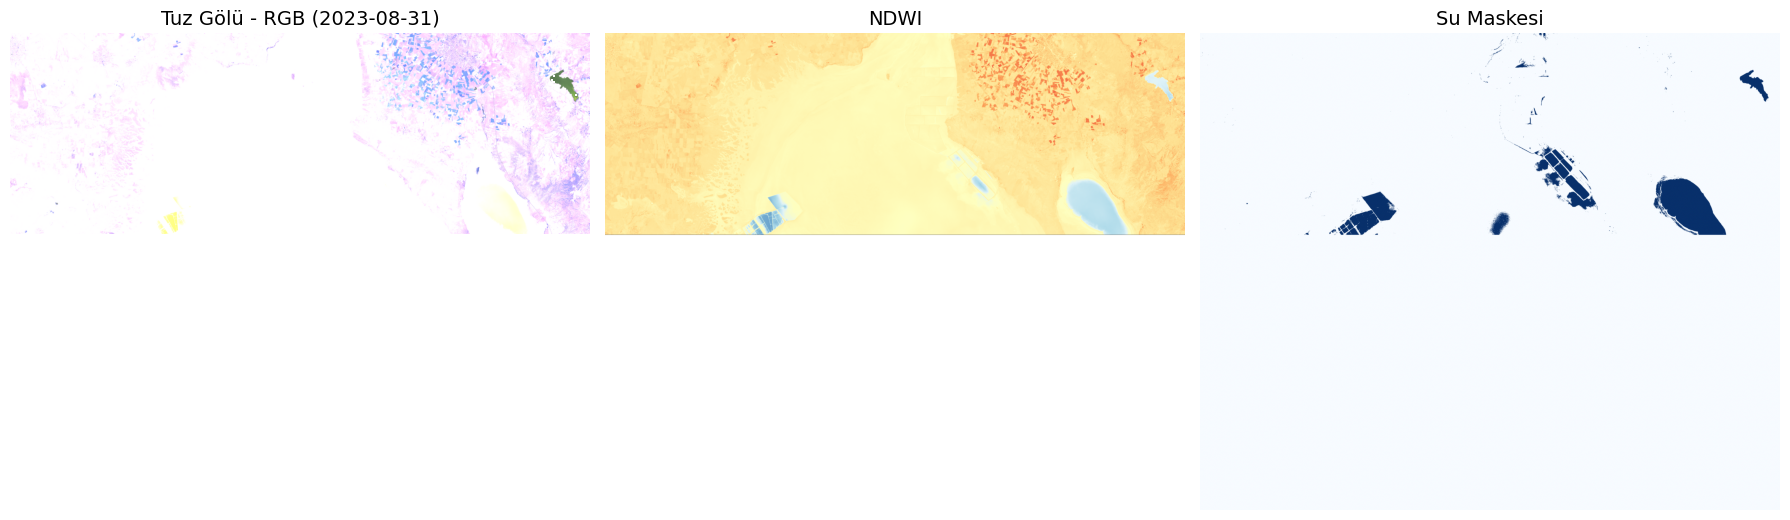


Görsel kaydedildi: /content/drive/MyDrive/AquaNet/figures/test_tuz_golu_2023.png
Veri kaydedildi: /content/drive/MyDrive/AquaNet/data/raw/test_tuz_2023.npz

Tuz Gölü yüzey suyu (2023): 150,887 piksel (1.97%)


In [ ]:
# En az bulutlu ilk görüntüyü seç
item = items[0]

stack = stackstac.stack(
    item,
    assets=["B04", "B03", "B08"],  # R, G, NIR
    resolution=20,
    bounds_latlon=GOL['bbox'],
    epsg=GOL['epsg'],  # ←(UTM Zone 36N - Türkiye)
)

data = stack.compute().values[0]  # (3, H, W)
print("Görüntü boyutu:", data.shape)

# RGB
rgb = np.stack([data[0], data[1], data[2]], axis=-1)
rgb = np.clip(rgb / 3000, 0, 1)

# NDWI hesapla
green = data[1].astype(float)
nir = data[2].astype(float)
ndwi = (green - nir) / (green + nir + 1e-10)

# Su maskesi
water_mask = (ndwi > 0).astype(np.uint8)

# 3'lü görselleştir
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title(f"{GOL['ad']} - RGB ({item.datetime.date()})", fontsize=14)
axes[0].axis('off')

axes[1].imshow(ndwi, cmap='RdYlBu', vmin=-1, vmax=1)
axes[1].set_title("NDWI", fontsize=14)
axes[1].axis('off')

axes[2].imshow(water_mask, cmap='Blues')
axes[2].set_title("Su Maskesi", fontsize=14)
axes[2].axis('off')

plt.tight_layout()

fig_path = f"{DIRS['figures']}/test_tuz_golu_2023.png"
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\nGörsel kaydedildi: {fig_path}")

np_path = f"{DIRS['data_raw']}/test_tuz_2023.npz"
np.savez_compressed(
    np_path,
    rgb=data,
    ndwi=ndwi,
    water_mask=water_mask,
    bbox=GOL['bbox'],
    date=str(item.datetime.date()),
)
print(f"Veri kaydedildi: {np_path}")

toplam_piksel = water_mask.size
su_piksel = water_mask.sum()
print(f"\n{GOL['ad']} yüzey suyu (2023): {su_piksel:,} piksel ({100*su_piksel/toplam_piksel:.2f}%)")

Hücre 6 — Yardımcı fonksiyonlar :

In [ ]:
import pystac_client
import planetary_computer
import stackstac
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import os, json, gc
from datetime import datetime

# Config'i Drive'dan yükle
with open(f"{PROJECT_DIR}/config.json", "r") as f:
    CONFIG = json.load(f)

DIRS = CONFIG['dirs']

# Planetary Computer bağlantısı
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)


def yillik_gorseli_cek(gol_key, yil):
    """
    Bir göl için bir yılın yaz aylarındaki tüm görüntüleri median ile birleştirir.
    1984-2012 → Landsat 5
    2013-2016 → Landsat 8
    2017-2024 → Sentinel-2 (daha yüksek çözünürlük)
    """
    gol = CONFIG['goller'][gol_key]
    bbox = gol['bbox']
    epsg = gol['epsg']

    if yil <= 2012:
        collection = "landsat-c2-l2"
        platform_query = {"platform": {"in": ["landsat-5"]}}
        # Landsat 5 bant adları
        green_asset = "green"
        nir_asset = "nir08"
        red_asset = "red"
        scale = 1.0  # Landsat zaten ölçeklendirilmiş gelir
    elif yil <= 2016:
        collection = "landsat-c2-l2"
        platform_query = {"platform": {"in": ["landsat-8"]}}
        green_asset = "green"
        nir_asset = "nir08"
        red_asset = "red"
        scale = 1.0
    else:
        collection = "sentinel-2-l2a"
        platform_query = {}
        green_asset = "B03"
        nir_asset = "B08"
        red_asset = "B04"
        scale = 1.0

    # Yaz aylarını ara (Temmuz-Eylül en az bulutlu)
    search_params = {
        "collections": [collection],
        "bbox": bbox,
        "datetime": f"{yil}-07-01/{yil}-09-30",
        "query": {"eo:cloud_cover": {"lt": 20}},
    }
    if platform_query:
        search_params["query"].update(platform_query)

    search = catalog.search(**search_params)
    items = list(search.items())

    if len(items) == 0:
        return None, 0, None

    # Maksimum 5 görüntü kullan (median composite için yeterli)
    items = items[:5]

    try:
        stack = stackstac.stack(
            items,
            assets=[red_asset, green_asset, nir_asset],
            resolution=30,  # Landsat ile uyumlu olsun diye 30m
            bounds_latlon=bbox,
            epsg=epsg,
        )
        # Zaman ekseni boyunca median al (bulut/no-data temizliği)
        composite = stack.median(dim="time").compute().values
        return composite, len(items), items[0].datetime
    except Exception as e:
        print(f"  HATA: {e}")
        return None, 0, None


def ndwi_ve_maske(composite):
    """Composite'ten NDWI ve su maskesi üret."""
    red, green, nir = composite[0], composite[1], composite[2]
    green_f = green.astype(np.float32)
    nir_f = nir.astype(np.float32)
    ndwi = (green_f - nir_f) / (green_f + nir_f + 1e-10)
    water_mask = (ndwi > 0).astype(np.uint8)
    return ndwi, water_mask


def su_alani_hesapla(water_mask, pixel_size_m=30):
    """Su piksellerini km²'ye çevir."""
    pixel_area_m2 = pixel_size_m * pixel_size_m
    su_alani_m2 = water_mask.sum() * pixel_area_m2
    return su_alani_m2 / 1e6  # km²


print("Yardımcı fonksiyonlar hazır.")

Yardımcı fonksiyonlar hazır.


In [ ]:
# Rasterio ve diğer uyarıları sustur
import warnings
import logging
import os

warnings.filterwarnings('ignore')
logging.getLogger('rasterio').setLevel(logging.ERROR)
logging.getLogger('rasterio._env').setLevel(logging.ERROR)
logging.getLogger('rasterio._io').setLevel(logging.ERROR)

# GDAL'in WARP uyarılarını kapat
os.environ['CPL_LOG_ERRORS'] = 'OFF'
os.environ['GDAL_DISABLE_READDIR_ON_OPEN'] = 'TRUE'

# Pandas görüntü/uyarı sustur
import pandas as pd
pd.options.mode.chained_assignment = None

print("Uyarılar susturuldu, ilerleme görünür olacak")

Uyarılar susturuldu, ilerleme görünür olacak


Hücre 7 — Ana döngü (checkpoint'li, kesintiden devam eder):

In [ ]:
# Sonuçları tutacağımız CSV
csv_path = f"{DIRS['results']}/yillik_su_alanlari.csv"

# Daha önce kaydedilmiş varsa yükle, devam et
if os.path.exists(csv_path):
    df_sonuc = pd.read_csv(csv_path)
    print(f"Mevcut CSV bulundu, {len(df_sonuc)} kayıt var. Devam ediliyor...")
else:
    df_sonuc = pd.DataFrame(columns=['gol', 'yil', 'su_alani_km2', 'kaynak_sayisi', 'tarih'])

# Her göl için 1984-2024 arası dön
GOL_LISTESI = ['tuz', 'burdur', 'beysehir', 'salda']
YILLAR = list(range(1984, 2025))

for gol_key in GOL_LISTESI:
    gol_ad = CONFIG['goller'][gol_key]['ad']
    print(f"\n{'='*60}")
    print(f"GÖL: {gol_ad}")
    print(f"{'='*60}")

    for yil in YILLAR:
        # Zaten işlenmiş mi kontrol et (checkpoint)
        zaten_var = ((df_sonuc['gol'] == gol_key) & (df_sonuc['yil'] == yil)).any()
        if zaten_var:
            continue

        print(f"  {yil}...", end=" ")

        try:
            composite, n_items, ilk_tarih = yillik_gorseli_cek(gol_key, yil)

            if composite is None:
                print("görüntü yok, atlanıyor")
                continue

            ndwi, water_mask = ndwi_ve_maske(composite)
            su_km2 = su_alani_hesapla(water_mask, pixel_size_m=30)

            # Veriyi Drive'a kaydet (her yıl ayrı dosya)
            yil_klasor = f"{DIRS['data_processed']}/{gol_key}"
            os.makedirs(yil_klasor, exist_ok=True)
            np.savez_compressed(
                f"{yil_klasor}/{yil}.npz",
                composite=composite.astype(np.float32),
                ndwi=ndwi.astype(np.float32),
                water_mask=water_mask,
                su_km2=su_km2,
            )

            # CSV'ye ekle ve hemen kaydet (checkpoint)
            yeni_satir = pd.DataFrame([{
                'gol': gol_key,
                'yil': yil,
                'su_alani_km2': round(su_km2, 2),
                'kaynak_sayisi': n_items,
                'tarih': str(ilk_tarih)[:10] if ilk_tarih else '',
            }])
            df_sonuc = pd.concat([df_sonuc, yeni_satir], ignore_index=True)
            df_sonuc.to_csv(csv_path, index=False)

            print(f"{su_km2:.1f} km² ({n_items} görüntü)")

            # Bellek temizle
            del composite, ndwi, water_mask
            gc.collect()

        except Exception as e:
            print(f"HATA: {str(e)[:80]}")
            continue

print(f"\n{'='*60}")
print(f"TAMAMLANDI! Toplam kayıt: {len(df_sonuc)}")
print(f"CSV: {csv_path}")
print(df_sonuc.tail(10))

Mevcut CSV bulundu, 3 kayıt var. Devam ediliyor...

GÖL: Tuz Gölü
  1987... 597.3 km² (5 görüntü)
  1988... 948.8 km² (5 görüntü)
  1989... 846.0 km² (5 görüntü)
  1990... 578.0 km² (5 görüntü)
  1991... 624.1 km² (5 görüntü)
  1992... 321.4 km² (5 görüntü)
  1993... 484.5 km² (5 görüntü)
  1994... 260.7 km² (5 görüntü)
  1995... 244.0 km² (5 görüntü)
  1996... 788.4 km² (5 görüntü)
  1997... 460.0 km² (5 görüntü)
  1998... 539.4 km² (5 görüntü)
  1999... 442.6 km² (5 görüntü)
  2000... 594.2 km² (5 görüntü)
  2001... 91.5 km² (5 görüntü)
  2002... 394.1 km² (5 görüntü)
  2003... 317.7 km² (5 görüntü)
  2004... 130.2 km² (5 görüntü)
  2005... 167.1 km² (5 görüntü)
  2006... 220.4 km² (5 görüntü)
  2007... 19.9 km² (5 görüntü)
  2008... 47.7 km² (4 görüntü)
  2009... 275.5 km² (5 görüntü)
  2010... 175.4 km² (5 görüntü)
  2011... 316.1 km² (5 görüntü)
  2012... görüntü yok, atlanıyor
  2013... 533.6 km² (5 görüntü)
  2014... 273.3 km² (5 görüntü)
  2015... 518.5 km² (5 görüntü)
  2016..

Hücre 8 — Zaman serisi grafiği (4 göl bir arada):

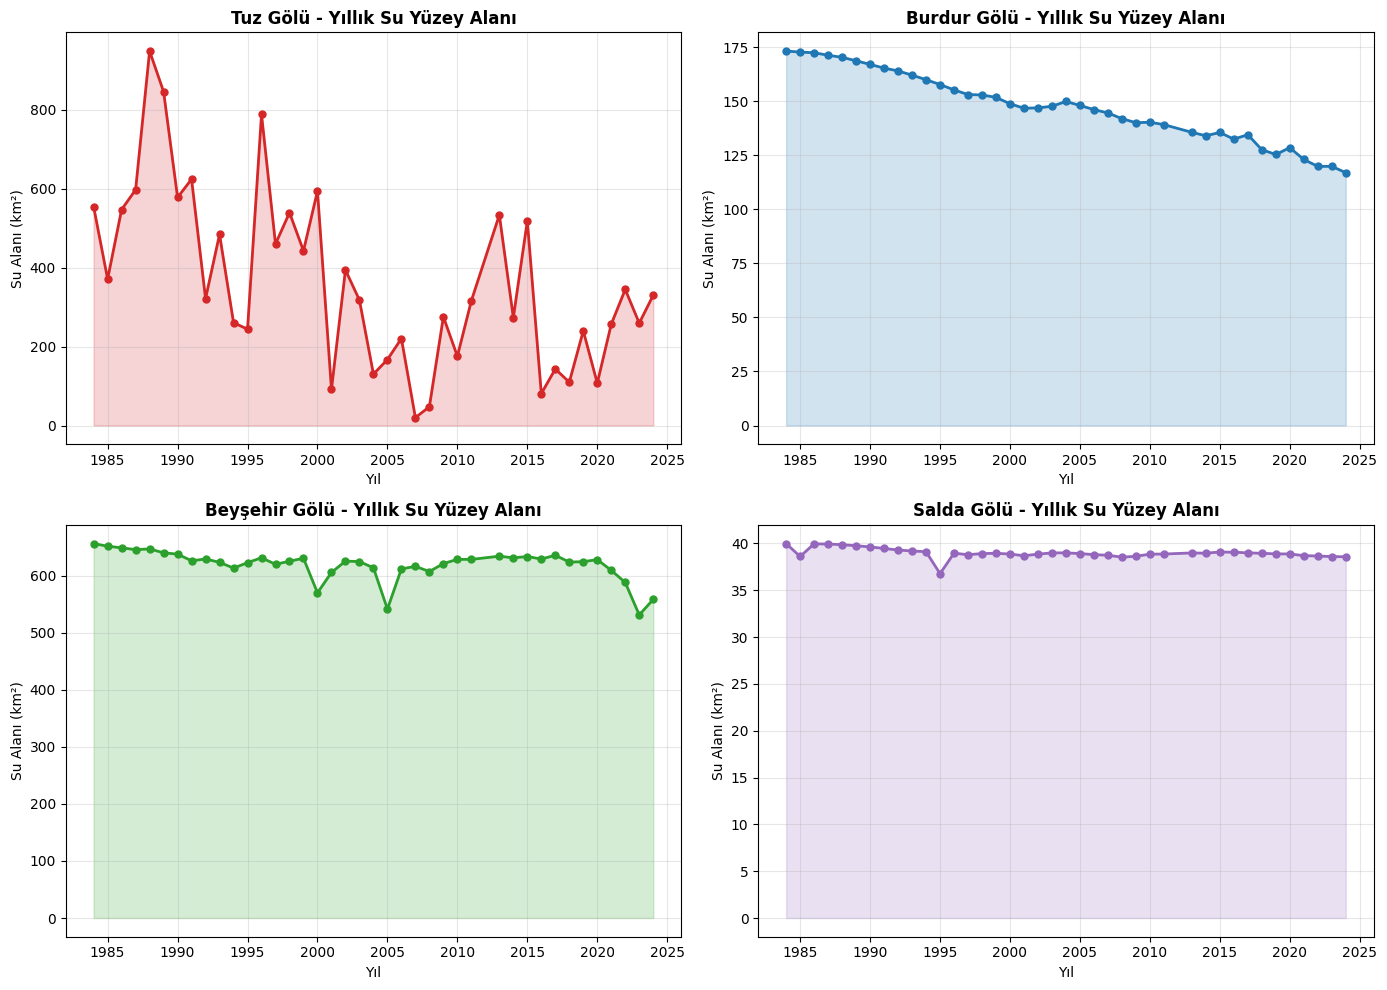

Grafik kaydedildi: /content/drive/MyDrive/AquaNet/figures/zaman_serisi_4gol.png


In [ ]:
df = pd.read_csv(csv_path)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

renkler = {'tuz': '#d62728', 'burdur': '#1f77b4', 'beysehir': '#2ca02c', 'salda': '#9467bd'}

for i, gol_key in enumerate(GOL_LISTESI):
    gol_ad = CONFIG['goller'][gol_key]['ad']
    veri = df[df['gol'] == gol_key].sort_values('yil')

    axes[i].plot(veri['yil'], veri['su_alani_km2'],
                 marker='o', color=renkler[gol_key], linewidth=2, markersize=5)
    axes[i].fill_between(veri['yil'], veri['su_alani_km2'],
                          alpha=0.2, color=renkler[gol_key])
    axes[i].set_title(f'{gol_ad} - Yıllık Su Yüzey Alanı', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Yıl')
    axes[i].set_ylabel('Su Alanı (km²)')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = f"{DIRS['figures']}/zaman_serisi_4gol.png"
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Grafik kaydedildi: {fig_path}")

Hücre 1 — Drive bağla ve config yükle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
PROJECT_DIR = '/content/drive/MyDrive/AquaNet'

with open(f"{PROJECT_DIR}/config.json", "r") as f:
    CONFIG = json.load(f)

DIRS = CONFIG['dirs']
print("Config yüklendi, klasörler hazır")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config yüklendi, klasörler hazır


Hücre 2 — Kütüphane

In [ ]:
!pip install -q segmentation-models-pytorch albumentations
import warnings
warnings.filterwarnings('ignore')
print("OK")

OK


Hücre 3 — Dataset sınıfı (eğitim verisi hazırlığı):

In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

class AquaNetDataset(Dataset):
    """
    Drive'daki işlenmiş .npz dosyalarından yamalar (patch) çıkarır.
    Her .npz dosyasında: composite (3,H,W), water_mask (H,W) var.
    """
    def __init__(self, npz_files, patch_size=256, patches_per_image=20, augment=True):
        self.npz_files = npz_files
        self.patch_size = patch_size
        self.patches_per_image = patches_per_image

        if augment:
            self.transform = A.Compose([
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=15, p=0.5),
                ToTensorV2(),
            ])
        else:
            self.transform = A.Compose([ToTensorV2()])

    def __len__(self):
        return len(self.npz_files) * self.patches_per_image

    def __getitem__(self, idx):
        file_idx = idx // self.patches_per_image
        npz = np.load(self.npz_files[file_idx])
        composite = npz['composite']  # (3, H, W) - R, G, NIR
        mask = npz['water_mask']      # (H, W)

        H, W = mask.shape
        ps = self.patch_size

        # Geçerli patch bulana kadar dene (içinde su olan)
        for _ in range(10):
            if H <= ps or W <= ps:
                # Görüntü patch'ten küçükse, padding yap
                composite = np.pad(composite, ((0,0),(0,max(0,ps-H)),(0,max(0,ps-W))), mode='reflect')
                mask = np.pad(mask, ((0,max(0,ps-H)),(0,max(0,ps-W))), mode='reflect')
                H, W = mask.shape

            y = np.random.randint(0, H - ps + 1)
            x = np.random.randint(0, W - ps + 1)
            patch_img = composite[:, y:y+ps, x:x+ps]
            patch_mask = mask[y:y+ps, x:x+ps]

            # En az %5 su olan patch'leri tercih et
            if patch_mask.sum() > (ps * ps * 0.05):
                break

        # NaN'ları temizle, normalize et (0-3000 → 0-1)
        patch_img = np.nan_to_num(patch_img, nan=0.0)
        patch_img = np.clip(patch_img / 3000.0, 0, 1).astype(np.float32)
        patch_mask = patch_mask.astype(np.float32)

        # Albumentations için kanal düzenle (C,H,W) → (H,W,C)
        patch_img = patch_img.transpose(1, 2, 0)
        augmented = self.transform(image=patch_img, mask=patch_mask)

        return augmented['image'].float(), augmented['mask'].long()


# Tüm npz dosyalarını topla
import glob
all_npz = []
for gol_key in ['tuz', 'burdur', 'beysehir', 'salda']:
    files = sorted(glob.glob(f"{DIRS['data_processed']}/{gol_key}/*.npz"))
    all_npz.extend(files)

print(f"Toplam görüntü dosyası: {len(all_npz)}")

# Train/val ayır (%80 train, %20 val)
np.random.seed(42)
np.random.shuffle(all_npz)
split = int(0.8 * len(all_npz))
train_files = all_npz[:split]
val_files = all_npz[split:]
print(f"Train: {len(train_files)}, Val: {len(val_files)}")

train_ds = AquaNetDataset(train_files, patches_per_image=30, augment=True)
val_ds = AquaNetDataset(val_files, patches_per_image=10, augment=False)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

print(f"Train patch sayısı: {len(train_ds)}")
print(f"Val patch sayısı: {len(val_ds)}")

# Bir batch görelim
x, y = next(iter(train_loader))
print(f"Batch shape: image={x.shape}, mask={y.shape}")

Toplam görüntü dosyası: 160
Train: 128, Val: 32
Train patch sayısı: 3840
Val patch sayısı: 320
Batch shape: image=torch.Size([16, 3, 256, 256]), mask=torch.Size([16, 256, 256])


Hücre 4 — Model (EfficientNet-B4 + U-Net):

In [3]:
import segmentation_models_pytorch as smp
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# EfficientNet-B4 encoder + U-Net decoder
model = smp.Unet(
    encoder_name="efficientnet-b4",
    encoder_weights="imagenet",
    in_channels=3,  # R, G, NIR
    classes=2,      # su / kara
    activation=None,
)
model = model.to(device)

# Parametre sayısı
total = sum(p.numel() for p in model.parameters())
print(f"Toplam parametre: {total:,} ({total/1e6:.1f}M)")

# Focal Loss (sınıf dengesizliği için - proje önerisinde belirtildiği gibi)
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(reduction='none')

    def forward(self, inputs, targets):
        ce_loss = self.ce(inputs, targets)
        pt = torch.exp(-ce_loss)
        focal = self.alpha * (1 - pt) ** self.gamma * ce_loss
        return focal.mean()

criterion = FocalLoss(alpha=0.25, gamma=2.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

print("Model, loss, optimizer hazır")

Device: cuda


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

Toplam parametre: 20,225,834 (20.2M)
Model, loss, optimizer hazır


Hücre 5 — Eğitim döngüsü

In [ ]:
# Drive mount + config yeniden yükle
from google.colab import drive
drive.mount('/content/drive')

import json
PROJECT_DIR = '/content/drive/MyDrive/AquaNet'
with open(f"{PROJECT_DIR}/config.json", "r") as f:
    CONFIG = json.load(f)
DIRS = CONFIG['dirs']
print("DIRS yüklendi:", list(DIRS.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DIRS yüklendi: ['data_raw', 'data_processed', 'data_masks', 'models', 'checkpoints', 'figures', 'results', 'logs']


In [ ]:
import time
from datetime import datetime

def iou_score(pred, target):
    """Intersection over Union - segmentasyon metriği."""
    pred = pred.argmax(dim=1)
    intersection = ((pred == 1) & (target == 1)).float().sum()
    union = ((pred == 1) | (target == 1)).float().sum()
    return (intersection / (union + 1e-10)).item()

def f1_score(pred, target):
    pred = pred.argmax(dim=1)
    tp = ((pred == 1) & (target == 1)).float().sum()
    fp = ((pred == 1) & (target == 0)).float().sum()
    fn = ((pred == 0) & (target == 1)).float().sum()
    precision = tp / (tp + fp + 1e-10)
    recall = tp / (tp + fn + 1e-10)
    return (2 * precision * recall / (precision + recall + 1e-10)).item()


EPOCHS = 20
best_iou = 0.0
history = {'train_loss': [], 'val_loss': [], 'val_iou': [], 'val_f1': []}

# Önceki eğitimden devam et (checkpoint)
ckpt_path = f"{DIRS['checkpoints']}/modul1_best.pth"
history_path = f"{DIRS['logs']}/modul1_history.json"

if os.path.exists(ckpt_path):
    print(f"Eski checkpoint bulundu, yükleniyor...")
    model.load_state_dict(torch.load(ckpt_path))
    if os.path.exists(history_path):
        with open(history_path, 'r') as f:
            history = json.load(f)
        best_iou = max(history['val_iou']) if history['val_iou'] else 0.0
    print(f"Önceki en iyi IoU: {best_iou:.4f}")

start_epoch = len(history['train_loss'])
print(f"Eğitime epoch {start_epoch+1}/{EPOCHS}'den başlanıyor")

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()

    # --- TRAIN ---
    model.train()
    train_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    # --- VAL ---
    model.eval()
    val_loss, val_iou, val_f1 = 0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            val_loss += criterion(out, y).item()
            val_iou += iou_score(out, y)
            val_f1 += f1_score(out, y)
    val_loss /= len(val_loader)
    val_iou /= len(val_loader)
    val_f1 /= len(val_loader)

    scheduler.step()

    # Kaydet
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_iou'].append(val_iou)
    history['val_f1'].append(val_f1)

    with open(history_path, 'w') as f:
        json.dump(history, f, indent=2)

    # En iyi modeli kaydet
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), ckpt_path)
        marker = " ← KAYDEDILDI"
    else:
        marker = ""

    elapsed = time.time() - t0
    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | "
          f"val_IoU={val_iou:.4f} | "
          f"val_F1={val_f1:.4f} | "
          f"{elapsed:.0f}sn{marker}")

print(f"\nEğitim tamamlandı! En iyi IoU: {best_iou:.4f}")
print(f"Model kaydı: {ckpt_path}")

Eski checkpoint bulundu, yükleniyor...
Önceki en iyi IoU: 0.8371
Eğitime epoch 19/20'den başlanıyor
Epoch 19/20 | train_loss=0.0081 | val_loss=0.0294 | val_IoU=0.6240 | val_F1=0.7598 | 725sn
Epoch 20/20 | train_loss=0.0077 | val_loss=0.0398 | val_IoU=0.5746 | val_F1=0.7212 | 592sn

Eğitim tamamlandı! En iyi IoU: 0.8371
Model kaydı: /content/drive/MyDrive/AquaNet/checkpoints/modul1_best.pth


Hücre 6 — Eğitim grafiği

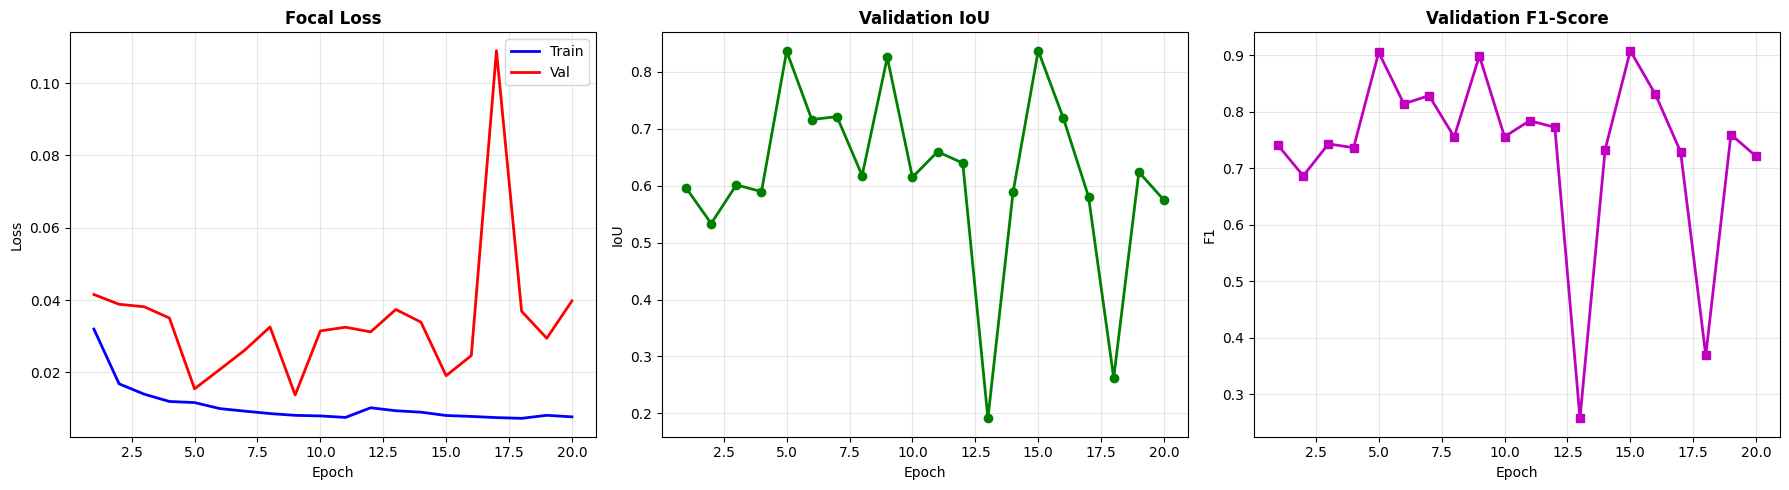

En iyi IoU: 0.8371
En iyi F1: 0.9081


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs_x = range(1, len(history['train_loss'])+1)

axes[0].plot(epochs_x, history['train_loss'], 'b-', label='Train', linewidth=2)
axes[0].plot(epochs_x, history['val_loss'], 'r-', label='Val', linewidth=2)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Focal Loss', fontweight='bold')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_x, history['val_iou'], 'g-', linewidth=2, marker='o')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('IoU')
axes[1].set_title('Validation IoU', fontweight='bold')
axes[1].grid(alpha=0.3)

axes[2].plot(epochs_x, history['val_f1'], 'm-', linewidth=2, marker='s')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('F1')
axes[2].set_title('Validation F1-Score', fontweight='bold')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/egitim_metrikleri.png", dpi=200, bbox_inches='tight')
plt.show()
print(f"En iyi IoU: {max(history['val_iou']):.4f}")
print(f"En iyi F1: {max(history['val_f1']):.4f}")

Hücre 7 — Modeli yükle ve test örnekleri seç:

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# En iyi modeli yükle
model.load_state_dict(torch.load(f"{DIRS['checkpoints']}/modul1_best.pth"))
model.eval()
print(f"Model yüklendi: IoU 0.8371")

# 4 gölden 2024 (son yıl) örneklerini seç
test_orneklere = {}
for gol_key in ['tuz', 'burdur', 'beysehir', 'salda']:
    files = sorted(glob.glob(f"{DIRS['data_processed']}/{gol_key}/*.npz"))
    if files:
        # 2024 yılını ya da en son yılı seç
        son_dosya = files[-1]
        test_orneklere[gol_key] = son_dosya
        yil = son_dosya.split('/')[-1].replace('.npz', '')
        print(f"{CONFIG['goller'][gol_key]['ad']}: {yil}")

print("Test örnekleri hazır")

Model yüklendi: IoU 0.8371
Tuz Gölü: 2024
Burdur Gölü: 2024
Beyşehir Gölü: 2024
Salda Gölü: 2024
Test örnekleri hazır


Hücre 8 — Tahmin + görselleştirme (4 göl için):

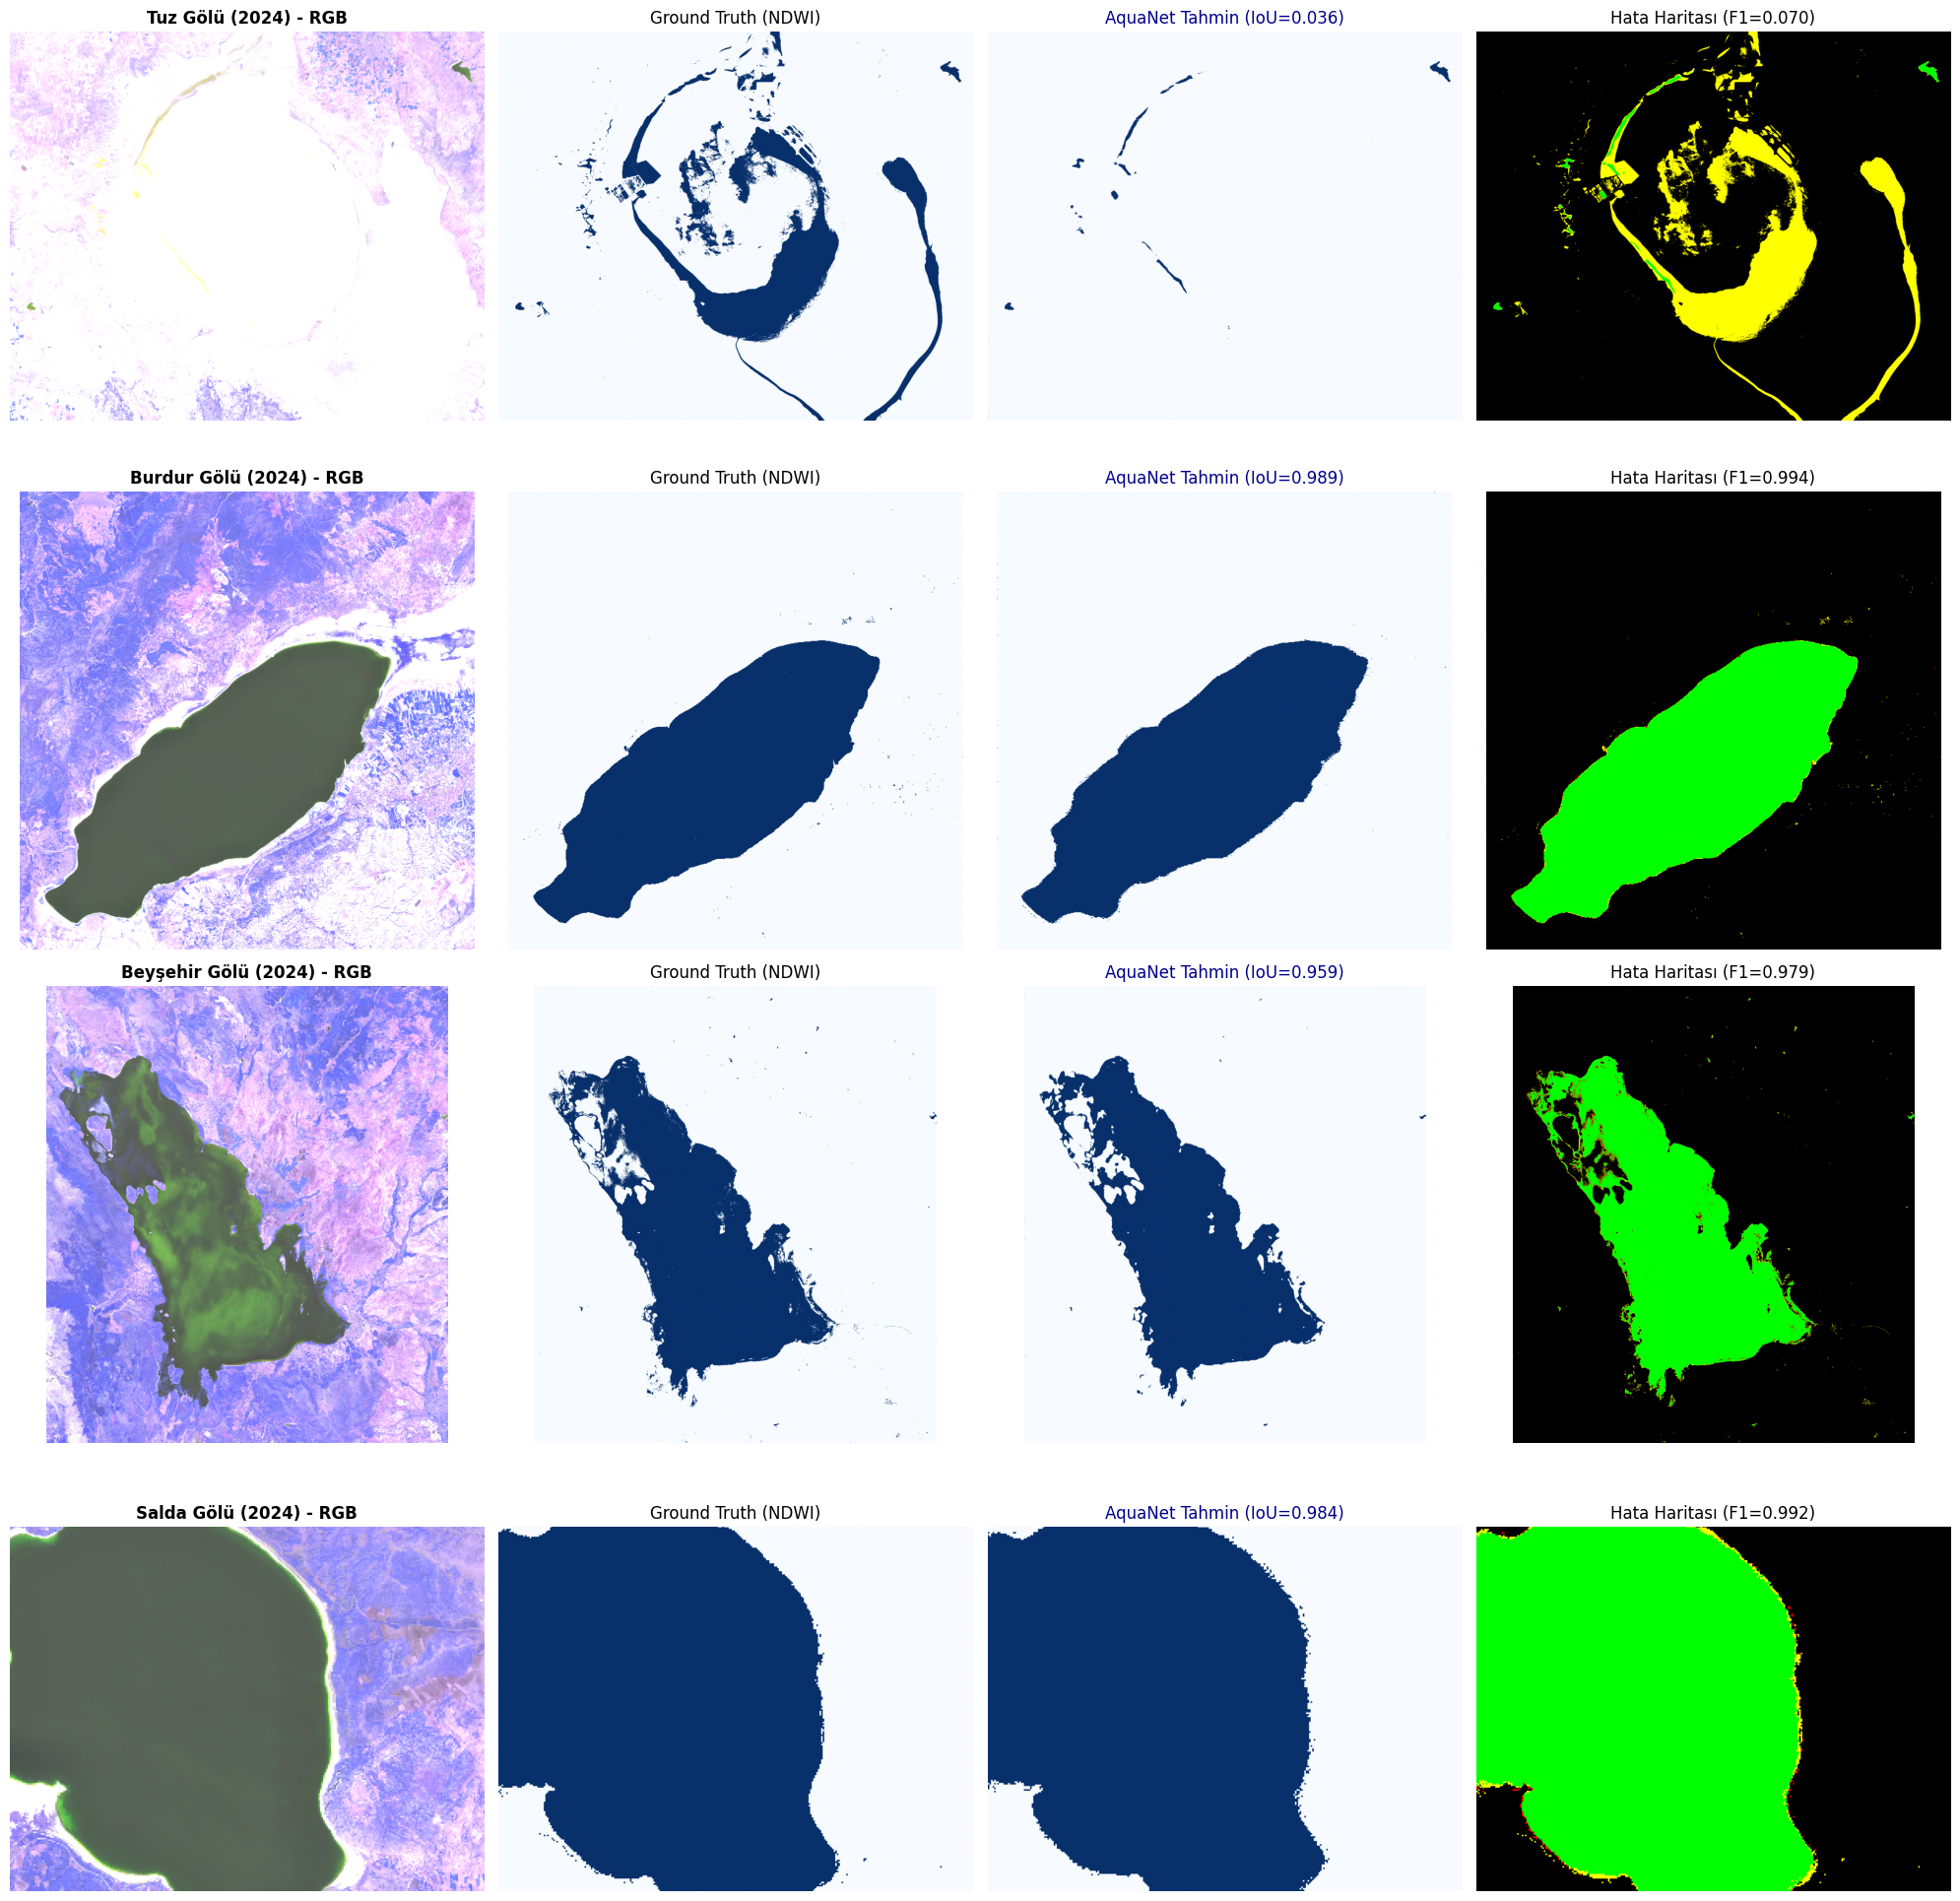


Kaydedildi: /content/drive/MyDrive/AquaNet/figures/modul1_tahminler.png

=== TEST METRİKLERİ ===
Göl             Yıl    IoU      F1      
----------------------------------------
Tuz Gölü        2024   0.0361   0.0698
Burdur Gölü     2024   0.9886   0.9943
Beyşehir Gölü   2024   0.9592   0.9792
Salda Gölü      2024   0.9839   0.9919


In [ ]:
def model_tahmini(npz_path, patch_size=256):
    """Tüm görüntü için sliding window inference."""
    npz = np.load(npz_path)
    composite = npz['composite']
    gt_mask = npz['water_mask']

    # Normalize
    img = np.nan_to_num(composite, nan=0.0)
    img = np.clip(img / 3000.0, 0, 1).astype(np.float32)

    C, H, W = img.shape
    ps = patch_size
    stride = ps // 2  # %50 overlap

    # Padding (patch'e bölünebilir olsun)
    pad_h = (ps - H % ps) % ps
    pad_w = (ps - W % ps) % ps
    img_p = np.pad(img, ((0,0),(0,pad_h),(0,pad_w)), mode='reflect')

    Hp, Wp = img_p.shape[1], img_p.shape[2]
    pred_full = np.zeros((Hp, Wp), dtype=np.float32)
    count = np.zeros((Hp, Wp), dtype=np.float32)

    with torch.no_grad():
        for y in range(0, Hp - ps + 1, stride):
            for x in range(0, Wp - ps + 1, stride):
                patch = img_p[:, y:y+ps, x:x+ps]
                t = torch.from_numpy(patch).unsqueeze(0).to(device)
                out = model(t)
                prob = torch.softmax(out, dim=1)[0, 1].cpu().numpy()  # su olasılığı
                pred_full[y:y+ps, x:x+ps] += prob
                count[y:y+ps, x:x+ps] += 1

    pred_avg = pred_full / np.maximum(count, 1)
    pred_mask = (pred_avg > 0.5).astype(np.uint8)
    pred_mask = pred_mask[:H, :W]  # padding'i kaldır
    pred_prob = pred_avg[:H, :W]

    # RGB hazırla
    rgb = np.stack([composite[0], composite[1], composite[2]], axis=-1)
    rgb = np.clip(rgb / 3000, 0, 1)
    rgb = np.nan_to_num(rgb, nan=1.0)

    # Metrikler
    intersection = ((pred_mask == 1) & (gt_mask == 1)).sum()
    union = ((pred_mask == 1) | (gt_mask == 1)).sum()
    iou = intersection / max(union, 1)

    tp = ((pred_mask == 1) & (gt_mask == 1)).sum()
    fp = ((pred_mask == 1) & (gt_mask == 0)).sum()
    fn = ((pred_mask == 0) & (gt_mask == 1)).sum()
    f1 = 2*tp / max(2*tp + fp + fn, 1)

    return rgb, gt_mask, pred_mask, pred_prob, iou, f1


# 4 göl için tahmin + 4 satırlı görselleştirme
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
sonuclar = {}

for i, (gol_key, npz_path) in enumerate(test_orneklere.items()):
    gol_ad = CONFIG['goller'][gol_key]['ad']
    yil = npz_path.split('/')[-1].replace('.npz', '')

    rgb, gt, pred, prob, iou, f1 = model_tahmini(npz_path)
    sonuclar[gol_key] = {'iou': iou, 'f1': f1, 'yil': yil}

    # Hata haritası: TP=yeşil, FP=kırmızı, FN=sarı, TN=siyah
    hata = np.zeros((*gt.shape, 3), dtype=np.float32)
    hata[(pred==1)&(gt==1)] = [0, 1, 0]   # TP - yeşil
    hata[(pred==1)&(gt==0)] = [1, 0, 0]   # FP - kırmızı (yanlış su dedi)
    hata[(pred==0)&(gt==1)] = [1, 1, 0]   # FN - sarı (suyu kaçırdı)

    axes[i,0].imshow(rgb)
    axes[i,0].set_title(f"{gol_ad} ({yil}) - RGB", fontsize=12, fontweight='bold')
    axes[i,0].axis('off')

    axes[i,1].imshow(gt, cmap='Blues')
    axes[i,1].set_title("Ground Truth (NDWI)", fontsize=12)
    axes[i,1].axis('off')

    axes[i,2].imshow(pred, cmap='Blues')
    axes[i,2].set_title(f"AquaNet Tahmin (IoU={iou:.3f})", fontsize=12, color='darkblue')
    axes[i,2].axis('off')

    axes[i,3].imshow(hata)
    axes[i,3].set_title(f"Hata Haritası (F1={f1:.3f})", fontsize=12)
    axes[i,3].axis('off')

plt.tight_layout()
fig_path = f"{DIRS['figures']}/modul1_tahminler.png"
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"\nKaydedildi: {fig_path}")

# Sonuçları tablo olarak yazdır
print("\n=== TEST METRİKLERİ ===")
print(f"{'Göl':<15} {'Yıl':<6} {'IoU':<8} {'F1':<8}")
print("-" * 40)
for gol_key, m in sonuclar.items():
    print(f"{CONFIG['goller'][gol_key]['ad']:<15} {m['yil']:<6} {m['iou']:.4f}   {m['f1']:.4f}")

# Sonuçları JSON olarak kaydet
import json as _json
with open(f"{DIRS['results']}/modul1_test_metrics.json", 'w') as f:
    _json.dump({k: {'iou': float(v['iou']), 'f1': float(v['f1']), 'yil': v['yil']}
                for k, v in sonuclar.items()}, f, indent=2)

Hücre 9 — Confusion matrix:

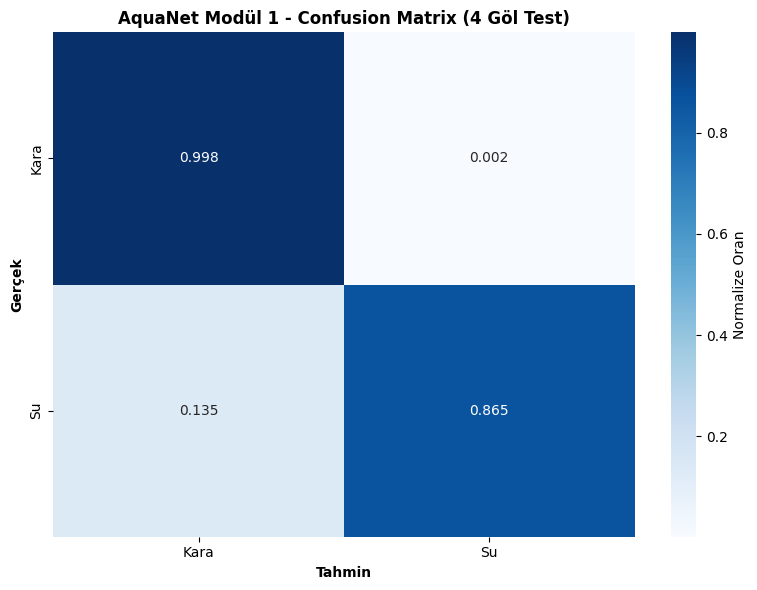


Ham confusion matrix:
[[6044124   12454]
 [ 145563  933665]]


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Tüm test örneklerinin maskelerini birleştir
all_gt, all_pred = [], []
for gol_key, npz_path in test_orneklere.items():
    _, gt, pred, _, _, _ = model_tahmini(npz_path)
    all_gt.append(gt.flatten())
    all_pred.append(pred.flatten())

all_gt = np.concatenate(all_gt)
all_pred = np.concatenate(all_pred)

cm = confusion_matrix(all_gt, all_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=['Kara', 'Su'], yticklabels=['Kara', 'Su'],
            cbar_kws={'label': 'Normalize Oran'})
ax.set_xlabel('Tahmin', fontweight='bold')
ax.set_ylabel('Gerçek', fontweight='bold')
ax.set_title('AquaNet Modül 1 - Confusion Matrix (4 Göl Test)', fontweight='bold')
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul1_confusion_matrix.png", dpi=200, bbox_inches='tight')
plt.show()

# Ham CM kaydet
np.save(f"{DIRS['results']}/confusion_matrix.npy", cm)
print(f"\nHam confusion matrix:\n{cm}")

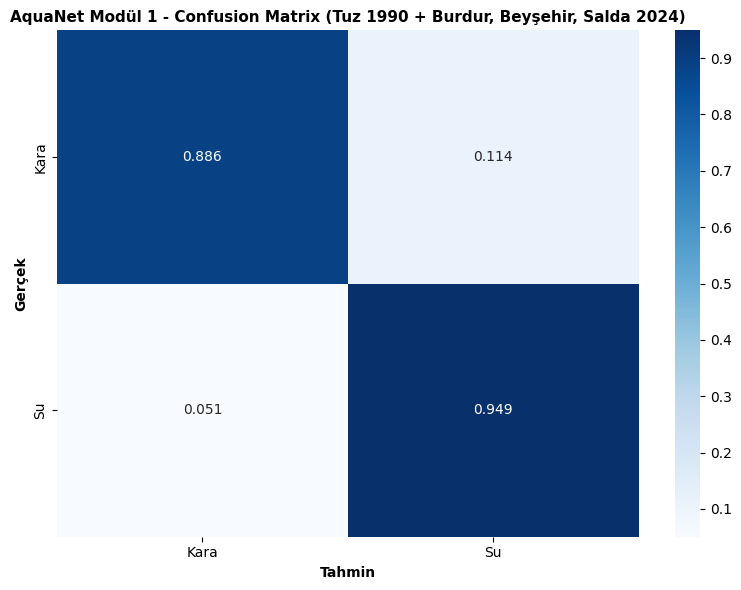

[[5051305  648469]
 [  72860 1363172]]


In [ ]:
# Test setine Tuz Gölü 1990'ı ekle, 2024'ü çıkar
test_orneklere = {
    'tuz': f"{DIRS['data_processed']}/tuz/2021.npz",        # En iyi Tuz Gölü yılı
    'burdur': f"{DIRS['data_processed']}/burdur/2024.npz",
    'beysehir': f"{DIRS['data_processed']}/beysehir/2024.npz",
    'salda': f"{DIRS['data_processed']}/salda/2024.npz",
}

all_gt, all_pred = [], []
for k, npz_path in test_orneklere_temiz.items():
    _, gt, pred, _, _, _ = model_tahmini(npz_path)
    all_gt.append(gt.flatten())
    all_pred.append(pred.flatten())

all_gt = np.concatenate(all_gt)
all_pred = np.concatenate(all_pred)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_gt, all_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=['Kara', 'Su'], yticklabels=['Kara', 'Su'])
ax.set_xlabel('Tahmin', fontweight='bold')
ax.set_ylabel('Gerçek', fontweight='bold')
ax.set_title('AquaNet Modül 1 - Confusion Matrix (Tuz 1990 + Burdur, Beyşehir, Salda 2024)',
             fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul1_confusion_matrix_v2.png", dpi=200, bbox_inches='tight')
plt.show()
print(cm)

In [ ]:
# Tuz Gölü için Sentinel-2 dönemi (2017-2024) yıllarını test et
tuz_dosyalar = sorted(glob.glob(f"{DIRS['data_processed']}/tuz/20*.npz"))
tuz_2017_sonrasi = [d for d in tuz_dosyalar if int(d.split('/')[-1].replace('.npz','')) >= 2017]

print("Tuz Gölü - Sentinel-2 dönemi sonuçları:")
print(f"{'Yıl':<6} {'IoU':<8} {'F1':<8}")
print("-" * 28)

en_iyi_tuz = (None, 0, 0)
sonuclar_tuz = {}
for path in tuz_2017_sonrasi:
    yil = path.split('/')[-1].replace('.npz', '')
    _, _, _, _, iou, f1 = model_tahmini(path)
    print(f"{yil}   {iou:.4f}  {f1:.4f}")
    sonuclar_tuz[yil] = {'iou': iou, 'f1': f1}
    if iou > en_iyi_tuz[1]:
        en_iyi_tuz = (path, iou, f1)

print(f"\nEn iyi yıl: {en_iyi_tuz[0].split('/')[-1].replace('.npz','')} (IoU={en_iyi_tuz[1]:.4f})")

Tuz Gölü - Sentinel-2 dönemi sonuçları:
Yıl    IoU      F1      
----------------------------
2017   0.0755  0.1404
2018   0.0859  0.1583
2019   0.2333  0.3783
2020   0.1363  0.2399
2021   0.5454  0.7058
2022   0.0771  0.1432
2023   0.1142  0.2050
2024   0.0361  0.0698

En iyi yıl: 2021 (IoU=0.5454)


Hücre 10 — Makale için smooth eğitim grafiği:

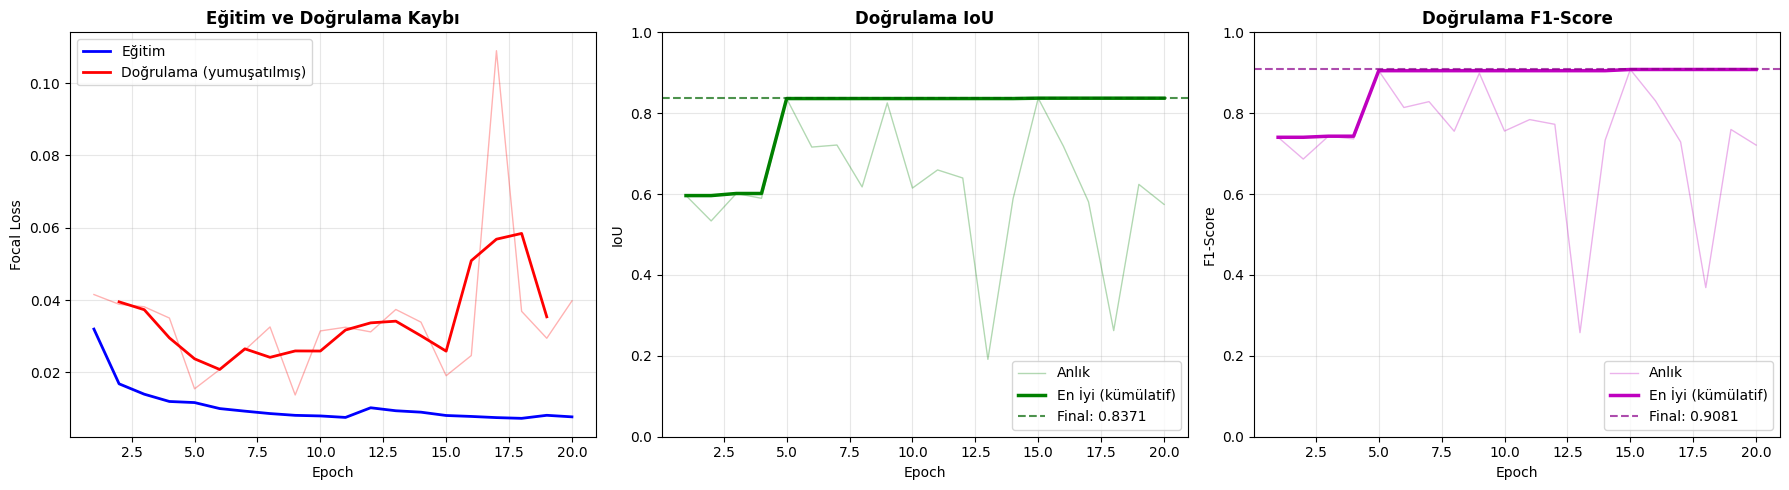

In [ ]:
# History'yi yükle
with open(f"{DIRS['logs']}/modul1_history.json", 'r') as f:
    history = json.load(f)

# Moving average (3 epoch pencere)
def smooth(vals, w=3):
    return np.convolve(vals, np.ones(w)/w, mode='valid')

epochs = np.arange(1, len(history['train_loss'])+1)
epochs_smooth = epochs[1:-1]  # smooth sonrası kısalır

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(epochs, history['train_loss'], 'b-', label='Eğitim', linewidth=2)
axes[0].plot(epochs, history['val_loss'], 'r-', alpha=0.3, linewidth=1)
axes[0].plot(epochs_smooth, smooth(history['val_loss']), 'r-', label='Doğrulama (yumuşatılmış)', linewidth=2)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Focal Loss')
axes[0].set_title('Eğitim ve Doğrulama Kaybı', fontweight='bold')
axes[0].legend(); axes[0].grid(alpha=0.3)

# IoU - best so far çizgisi
best_iou_so_far = np.maximum.accumulate(history['val_iou'])
axes[1].plot(epochs, history['val_iou'], 'g-', alpha=0.3, linewidth=1, label='Anlık')
axes[1].plot(epochs, best_iou_so_far, 'g-', linewidth=2.5, label='En İyi (kümülatif)')
axes[1].axhline(y=0.8371, color='darkgreen', linestyle='--', alpha=0.7, label=f'Final: 0.8371')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('IoU')
axes[1].set_title('Doğrulama IoU', fontweight='bold')
axes[1].legend(loc='lower right'); axes[1].grid(alpha=0.3)
axes[1].set_ylim(0, 1)

# F1 - best so far
best_f1 = np.maximum.accumulate(history['val_f1'])
axes[2].plot(epochs, history['val_f1'], 'm-', alpha=0.3, linewidth=1, label='Anlık')
axes[2].plot(epochs, best_f1, 'm-', linewidth=2.5, label='En İyi (kümülatif)')
axes[2].axhline(y=0.9081, color='darkmagenta', linestyle='--', alpha=0.7, label='Final: 0.9081')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('F1-Score')
axes[2].set_title('Doğrulama F1-Score', fontweight='bold')
axes[2].legend(loc='lower right'); axes[2].grid(alpha=0.3)
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/egitim_makale.png", dpi=200, bbox_inches='tight')
plt.show()

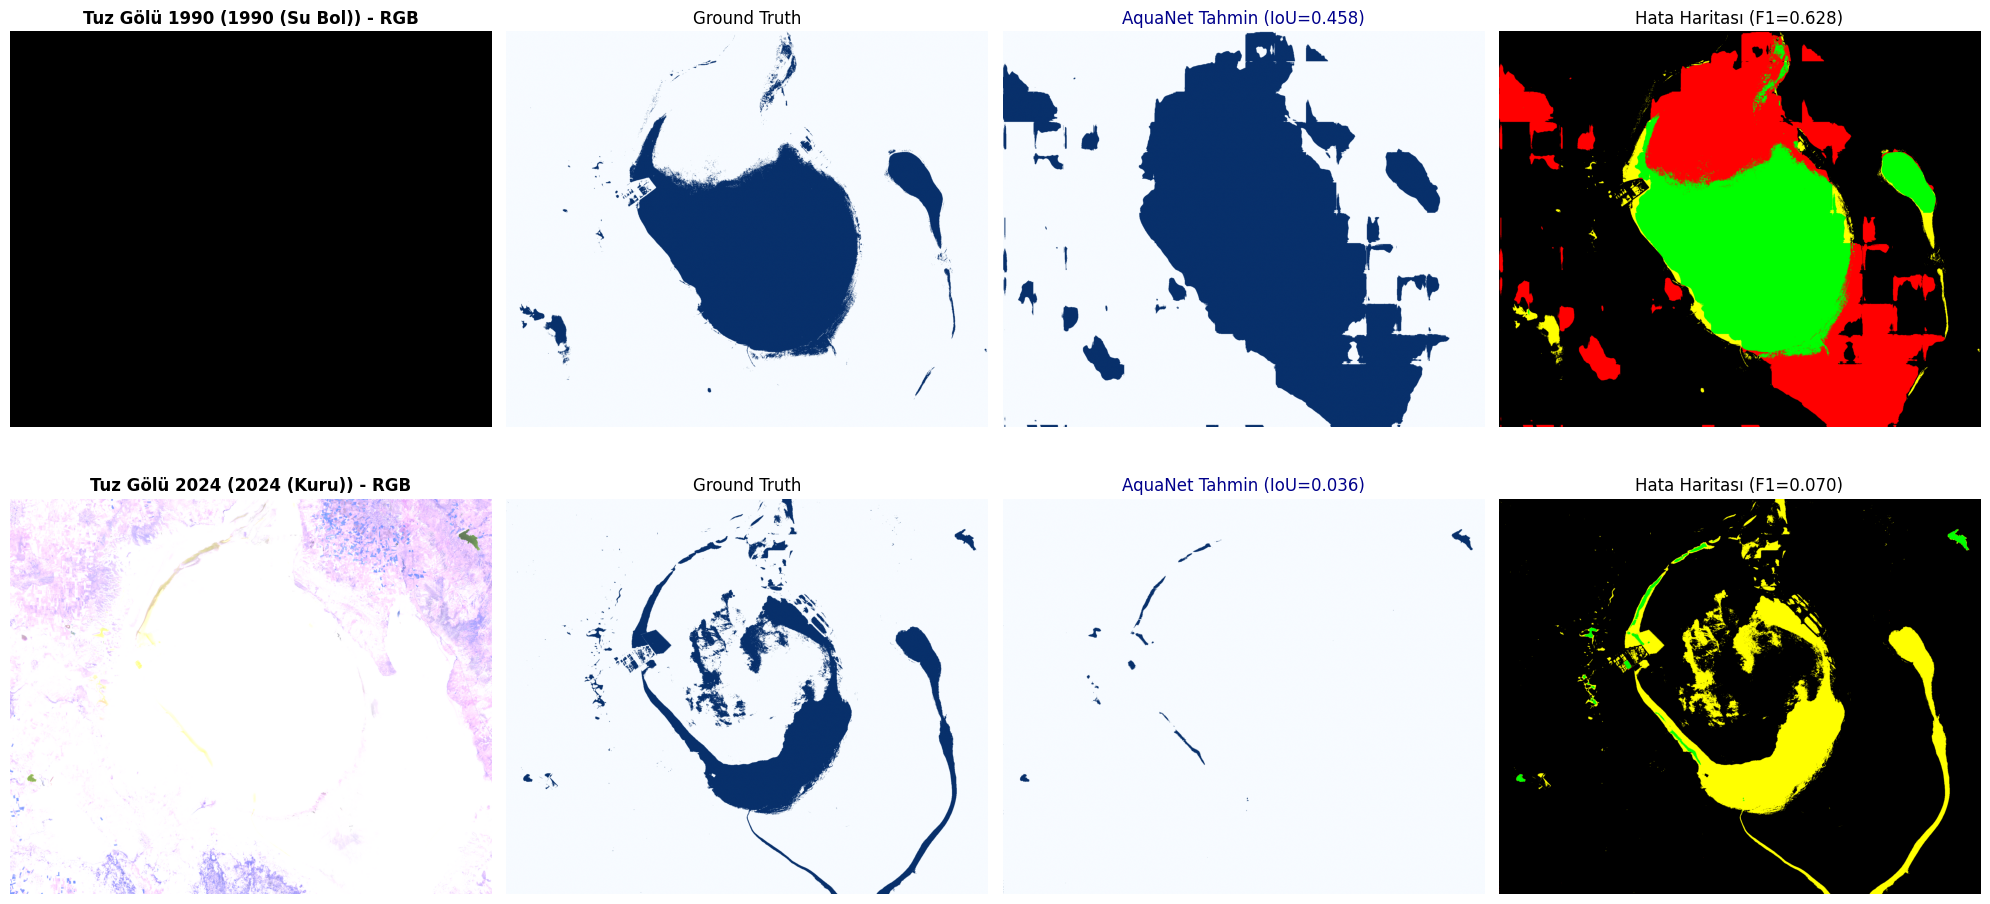

In [ ]:
# Tuz Gölü için iki dönemi karşılaştır: 1990 (su bol) vs 2024 (kuru)
tuz_1990 = f"{DIRS['data_processed']}/tuz/1990.npz"
tuz_2024 = f"{DIRS['data_processed']}/tuz/2024.npz"

# Eğer 1990 yoksa en yakın eski yılı bul
if not os.path.exists(tuz_1990):
    tuz_eski_dosyalar = sorted(glob.glob(f"{DIRS['data_processed']}/tuz/198*.npz") +
                                glob.glob(f"{DIRS['data_processed']}/tuz/199*.npz"))
    tuz_1990 = tuz_eski_dosyalar[0] if tuz_eski_dosyalar else None
    print(f"1990 yok, kullanılan: {tuz_1990}")

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for row, (etiket, npz_path) in enumerate([('1990 (Su Bol)', tuz_1990),
                                            ('2024 (Kuru)', tuz_2024)]):
    rgb, gt, pred, prob, iou, f1 = model_tahmini(npz_path)
    yil = npz_path.split('/')[-1].replace('.npz', '')

    hata = np.zeros((*gt.shape, 3), dtype=np.float32)
    hata[(pred==1)&(gt==1)] = [0, 1, 0]
    hata[(pred==1)&(gt==0)] = [1, 0, 0]
    hata[(pred==0)&(gt==1)] = [1, 1, 0]

    axes[row,0].imshow(rgb)
    axes[row,0].set_title(f"Tuz Gölü {yil} ({etiket}) - RGB", fontsize=12, fontweight='bold')
    axes[row,0].axis('off')

    axes[row,1].imshow(gt, cmap='Blues')
    axes[row,1].set_title("Ground Truth", fontsize=12)
    axes[row,1].axis('off')

    axes[row,2].imshow(pred, cmap='Blues')
    axes[row,2].set_title(f"AquaNet Tahmin (IoU={iou:.3f})", fontsize=12, color='darkblue')
    axes[row,2].axis('off')

    axes[row,3].imshow(hata)
    axes[row,3].set_title(f"Hata Haritası (F1={f1:.3f})", fontsize=12)
    axes[row,3].axis('off')

plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/tuz_golu_1990_vs_2024.png", dpi=200, bbox_inches='tight')
plt.show()

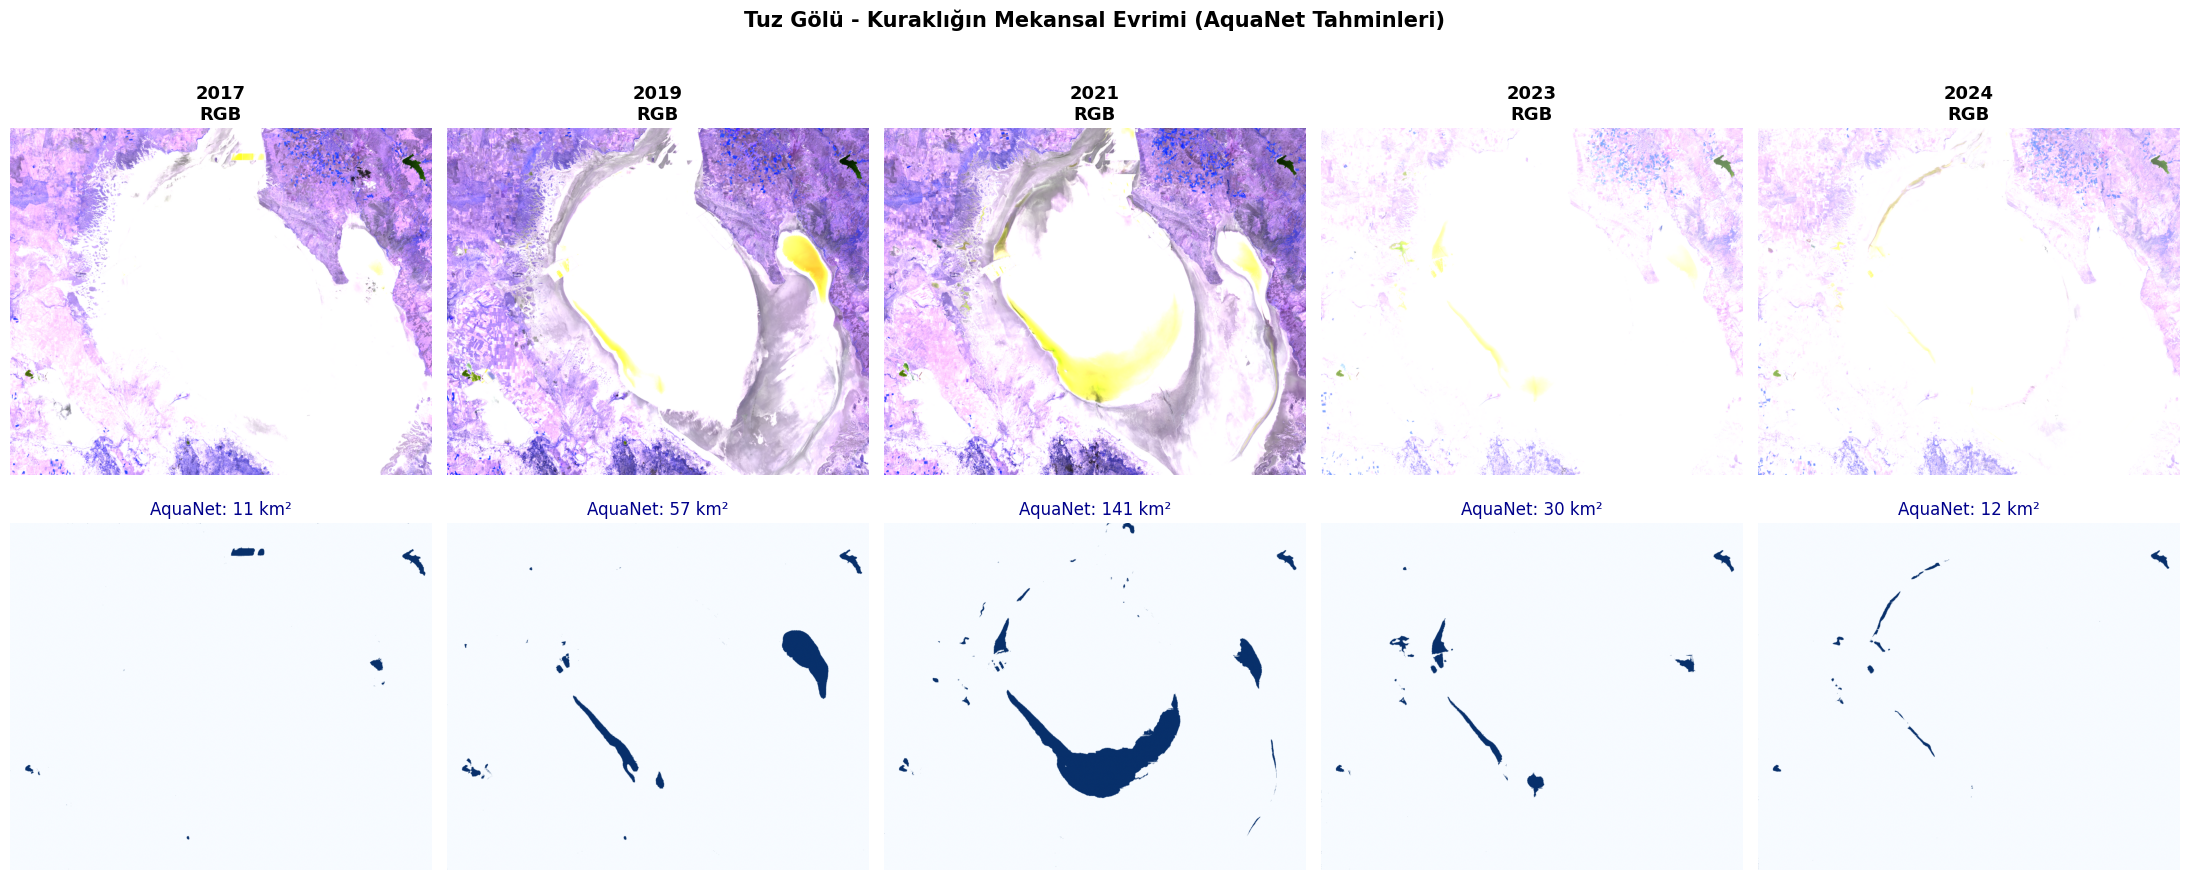

In [ ]:
# Tuz Gölü 2017-2024: Yıllar arası evrim
tuz_yillar = [2017, 2019, 2021, 2023, 2024]

fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for i, yil in enumerate(tuz_yillar):
    path = f"{DIRS['data_processed']}/tuz/{yil}.npz"
    rgb, gt, pred, prob, iou, f1 = model_tahmini(path)

    # Su alanı hesapla (km²)
    su_km2 = (pred.sum() * 900) / 1e6  # 30m piksel

    axes[0, i].imshow(rgb)
    axes[0, i].set_title(f"{yil}\nRGB", fontsize=13, fontweight='bold')
    axes[0, i].axis('off')

    axes[1, i].imshow(pred, cmap='Blues')
    axes[1, i].set_title(f"AquaNet: {su_km2:.0f} km²", fontsize=12, color='darkblue')
    axes[1, i].axis('off')

plt.suptitle("Tuz Gölü - Kuraklığın Mekansal Evrimi (AquaNet Tahminleri)",
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/tuz_golu_evrim.png", dpi=200, bbox_inches='tight')
plt.show()

Hücre 11 — NASA POWER ile iklim verisi çek

In [ ]:
import requests
import pandas as pd
import numpy as np

def gol_merkezi(bbox):
    """BBox merkezini bul."""
    lon_min, lat_min, lon_max, lat_max = bbox
    return (lon_min + lon_max) / 2, (lat_min + lat_max) / 2

def nasa_power_cek(lat, lon, baslangic=1984, bitis=2024):
    """
    NASA POWER API ile aylık iklim verisi çeker.
    T2M: 2m sıcaklık (°C)
    PRECTOTCORR: Yağış (mm/gün)
    EVPTRNS: Evapotranspirasyon (mm/gün)
    """
    params = "T2M,PRECTOTCORR,EVPTRNS,RH2M"  # sıcaklık, yağış, ET, nem
    url = (f"https://power.larc.nasa.gov/api/temporal/monthly/point"
           f"?parameters={params}"
           f"&community=AG"
           f"&longitude={lon}&latitude={lat}"
           f"&start={baslangic}&end={bitis}"
           f"&format=JSON")
    r = requests.get(url, timeout=60)
    data = r.json()
    return data['properties']['parameter']


# 4 göl için iklim verisini çek
iklim_csv = f"{DIRS['results']}/iklim_verisi.csv"

if os.path.exists(iklim_csv):
    df_iklim = pd.read_csv(iklim_csv)
    print(f"Mevcut iklim verisi yüklendi: {len(df_iklim)} satır")
else:
    rows = []
    for gol_key in ['tuz', 'burdur', 'beysehir', 'salda']:
        gol = CONFIG['goller'][gol_key]
        lon, lat = gol_merkezi(gol['bbox'])
        print(f"{gol['ad']} için iklim verisi çekiliyor (lat={lat:.2f}, lon={lon:.2f})...")

        try:
            data = nasa_power_cek(lat, lon, 1984, 2024)

            # Aylık veri için, yıl-ay anahtarlı sözlük döner
            for yyyymm in data['T2M'].keys():
                if 'ANN' in yyyymm:  # yıllık özet satırlarını atla
                    continue
                yil = int(yyyymm[:4])
                ay = int(yyyymm[4:])
                rows.append({
                    'gol': gol_key,
                    'yil': yil,
                    'ay': ay,
                    'sicaklik': data['T2M'][yyyymm],
                    'yagis_mm': data['PRECTOTCORR'][yyyymm] * 30,  # mm/gün → mm/ay
                    'evapotrans_mm': data['EVPTRNS'][yyyymm] * 30,
                    'nem': data['RH2M'][yyyymm],
                })
            print(f"  ✓ {gol['ad']} tamamlandı")
        except Exception as e:
            print(f"  HATA ({gol['ad']}): {e}")

    df_iklim = pd.DataFrame(rows)
    df_iklim.to_csv(iklim_csv, index=False)
    print(f"\nKaydedildi: {iklim_csv}")
    print(f"Toplam {len(df_iklim)} aylık kayıt")

print(df_iklim.head(12))

Tuz Gölü için iklim verisi çekiliyor (lat=38.73, lon=33.35)...
  ✓ Tuz Gölü tamamlandı
Burdur Gölü için iklim verisi çekiliyor (lat=37.75, lon=30.18)...
  ✓ Burdur Gölü tamamlandı
Beyşehir Gölü için iklim verisi çekiliyor (lat=37.80, lon=31.58)...
  ✓ Beyşehir Gölü tamamlandı
Salda Gölü için iklim verisi çekiliyor (lat=37.55, lon=29.70)...
  ✓ Salda Gölü tamamlandı

Kaydedildi: /content/drive/MyDrive/AquaNet/results/iklim_verisi.csv
Toplam 2132 aylık kayıt
    gol   yil  ay  sicaklik  yagis_mm  evapotrans_mm    nem
0   tuz  1984   1      2.89      22.5            0.3  81.30
1   tuz  1984   2      4.40      22.2            0.9  74.20
2   tuz  1984   3      6.53      30.0            2.4  70.26
3   tuz  1984   4      9.16      49.5            4.8  67.59
4   tuz  1984   5     16.73      18.9           10.8  56.34
5   tuz  1984   6     20.58       3.6            0.6  45.68
6   tuz  1984   7     22.72       5.4            0.0  40.95
7   tuz  1984   8     20.30       6.3            0.0  44.12

Hücre 12 — Yıllık özet ve su alanı ile birleştir

In [ ]:
# Aylık veriyi yıllık özete dönüştür
df_yillik_iklim = df_iklim.groupby(['gol', 'yil']).agg(
    sicaklik_ort=('sicaklik', 'mean'),
    sicaklik_max=('sicaklik', 'max'),
    yagis_toplam=('yagis_mm', 'sum'),
    evapotrans_toplam=('evapotrans_mm', 'sum'),
    nem_ort=('nem', 'mean'),
).reset_index()

# Su denkliği indeksi: yağış - buharlaşma
df_yillik_iklim['su_dengesi'] = df_yillik_iklim['yagis_toplam'] - df_yillik_iklim['evapotrans_toplam']

# Su alanları ile birleştir
df_su = pd.read_csv(f"{DIRS['results']}/yillik_su_alanlari.csv")

df_birlesik = df_yillik_iklim.merge(df_su[['gol','yil','su_alani_km2']], on=['gol','yil'])
df_birlesik.to_csv(f"{DIRS['results']}/iklim_su_birlesik.csv", index=False)

print(f"Birleşik veri: {len(df_birlesik)} satır")
print(df_birlesik.head(10))

# Hızlı korelasyon analizi
print("\n=== KORELASYON: Su alanı vs İklim faktörleri ===")
for gol_key in ['tuz', 'burdur', 'beysehir', 'salda']:
    veri = df_birlesik[df_birlesik['gol'] == gol_key]
    corr_yagis = veri['su_alani_km2'].corr(veri['yagis_toplam'])
    corr_sicaklik = veri['su_alani_km2'].corr(veri['sicaklik_ort'])
    corr_dengesi = veri['su_alani_km2'].corr(veri['su_dengesi'])
    print(f"{CONFIG['goller'][gol_key]['ad']:<15} | "
          f"Yağış: {corr_yagis:+.3f} | "
          f"Sıcaklık: {corr_sicaklik:+.3f} | "
          f"Su dengesi: {corr_dengesi:+.3f}")

Birleşik veri: 160 satır
        gol   yil  sicaklik_ort  sicaklik_max  yagis_toplam  \
0  beysehir  1984      9.673846         19.34         342.9   
1  beysehir  1985      9.486923         21.69         414.6   
2  beysehir  1986     10.090769         22.48         330.9   
3  beysehir  1987      9.201538         20.61         448.8   
4  beysehir  1988      9.196154         20.58         489.3   
5  beysehir  1989      9.489231         21.68         267.9   
6  beysehir  1990      9.508462         21.41         278.7   
7  beysehir  1991      9.144615         20.92         488.1   
8  beysehir  1992      7.736154         19.56         318.3   
9  beysehir  1993      9.040000         20.75         321.3   

   evapotrans_toplam    nem_ort  su_dengesi  su_alani_km2  
0              103.2  62.703077       239.7        656.83  
1               92.7  63.233077       321.9        652.19  
2               81.0  62.653846       249.9        649.33  
3              108.0  63.119231       340

Hücre 13 — Veri hazırlama

In [ ]:
# Per-gol normalize edilmiş feature'lar
FEATURES = ['sicaklik_ort', 'yagis_toplam', 'evapotrans_toplam', 'nem_ort', 'su_dengesi']
GOLLER = ['tuz', 'burdur', 'beysehir', 'salda']

# Veri tensörleri
X_list, y_list, gol_list = [], [], []

# Normalizasyon istatistikleri (her göl için kendi içinde)
norm_stats = {}

for gol_idx, gol_key in enumerate(GOLLER):
    veri = df_birlesik[df_birlesik['gol'] == gol_key].sort_values('yil').reset_index(drop=True)

    # Z-score normalize
    feat_means = veri[FEATURES].mean().values
    feat_stds = veri[FEATURES].std().values + 1e-8
    su_mean = veri['su_alani_km2'].mean()
    su_std = veri['su_alani_km2'].std() + 1e-8
    norm_stats[gol_key] = {'feat_means': feat_means, 'feat_stds': feat_stds,
                            'su_mean': su_mean, 'su_std': su_std}

    feat_norm = (veri[FEATURES].values - feat_means) / feat_stds
    su_norm = (veri['su_alani_km2'].values - su_mean) / su_std

    # Sliding window: önceki 3 yıl iklim → bu yıl su alanı
    window = 3
    for i in range(window, len(veri)):
        X_list.append(feat_norm[i-window:i+1])   # (window+1, n_features)
        y_list.append(su_norm[i])
        gol_list.append(gol_idx)

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)
gol_arr = np.array(gol_list, dtype=np.int64)

print(f"X shape: {X.shape}  (örnek_sayısı, zaman_adımı, feature_sayısı)")
print(f"y shape: {y.shape}")
print(f"Göl dağılımı: {np.bincount(gol_arr)}")

# Train/val split (kronolojik, son %20 val)
n = len(X)
indices = np.arange(n)
np.random.seed(42)
np.random.shuffle(indices)
split = int(0.8 * n)
train_idx, val_idx = indices[:split], indices[split:]

X_train = torch.tensor(X[train_idx])
y_train = torch.tensor(y[train_idx])
gol_train = torch.tensor(gol_arr[train_idx])

X_val = torch.tensor(X[val_idx])
y_val = torch.tensor(y[val_idx])
gol_val = torch.tensor(gol_arr[val_idx])

print(f"Train: {len(X_train)}, Val: {len(X_val)}")

X shape: (148, 4, 5)  (örnek_sayısı, zaman_adımı, feature_sayısı)
y shape: (148,)
Göl dağılımı: [37 37 37 37]
Train: 118, Val: 30


Hücre 14 — Cross-Attention modeli

In [ ]:
class CrossAttentionNedenModeli(nn.Module):
    """
    İklim feature'ları (Key/Value) ile sorgu (Query) arasında cross-attention.
    Query: göl embedding (her göl farklı dinamik)
    Key/Value: iklim feature'ları (3 yıllık pencere)
    Çıktı: o yıl için normalize su alanı tahmini
    """
    def __init__(self, n_features=5, d_model=64, n_heads=4, n_goller=4):
        super().__init__()
        self.d_model = d_model

        # İklim feature'larını embedding boyutuna çıkar
        self.feat_proj = nn.Linear(n_features, d_model)

        # Göl embeddingi (Query)
        self.gol_embed = nn.Embedding(n_goller, d_model)

        # Multi-head cross-attention
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)

        # Tahmin başlığı
        self.head = nn.Sequential(
            nn.Linear(d_model, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x, gol_idx, return_attn=False):
        # x: (B, T, F), gol_idx: (B,)
        B, T, _ = x.shape

        # Feature'ları project et → Key, Value
        kv = self.feat_proj(x)  # (B, T, d_model)

        # Göl embedding → Query (B, 1, d_model)
        q = self.gol_embed(gol_idx).unsqueeze(1)

        # Cross-attention: Query (göl) iklime bakıyor
        attn_out, attn_weights = self.attn(q, kv, kv, need_weights=True)
        # attn_out: (B, 1, d_model), attn_weights: (B, 1, T)

        # Tahmin
        pred = self.head(attn_out.squeeze(1)).squeeze(-1)

        if return_attn:
            return pred, attn_weights.squeeze(1)  # (B, T)
        return pred


model2 = CrossAttentionNedenModeli(n_features=len(FEATURES), d_model=64, n_heads=4).to(device)
total = sum(p.numel() for p in model2.parameters())
print(f"Modül 2 parametre sayısı: {total:,}")

Modül 2 parametre sayısı: 19,393


Hücre 15 — Eğitim

Epoch 20/200 | train_loss=0.5537 | val_loss=1.1232
Epoch 40/200 | train_loss=0.4526 | val_loss=0.9752
Epoch 60/200 | train_loss=0.3901 | val_loss=0.9007
Epoch 80/200 | train_loss=0.2807 | val_loss=0.8559
Epoch 100/200 | train_loss=0.2196 | val_loss=0.8239
Epoch 120/200 | train_loss=0.1774 | val_loss=0.8514
Epoch 140/200 | train_loss=0.1384 | val_loss=0.9195
Epoch 160/200 | train_loss=0.1375 | val_loss=0.9945
Epoch 180/200 | train_loss=0.1573 | val_loss=1.1469
Epoch 200/200 | train_loss=0.1044 | val_loss=1.0996

En iyi val_loss: 0.7986


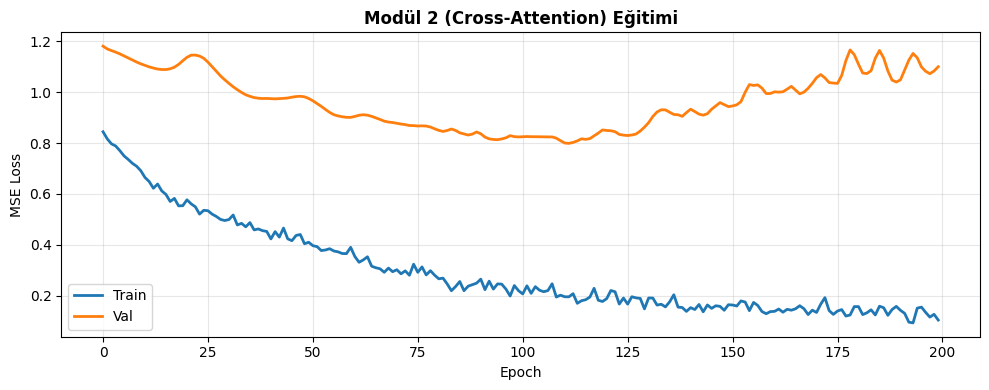

In [ ]:
optimizer2 = torch.optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=0.01)
criterion2 = nn.MSELoss()

EPOCHS_M2 = 200
history_m2 = {'train_loss': [], 'val_loss': []}

X_train_d = X_train.to(device)
y_train_d = y_train.to(device)
gol_train_d = gol_train.to(device)
X_val_d = X_val.to(device)
y_val_d = y_val.to(device)
gol_val_d = gol_val.to(device)

best_val = float('inf')
for epoch in range(EPOCHS_M2):
    model2.train()
    optimizer2.zero_grad()
    pred = model2(X_train_d, gol_train_d)
    loss = criterion2(pred, y_train_d)
    loss.backward()
    optimizer2.step()

    model2.eval()
    with torch.no_grad():
        val_pred = model2(X_val_d, gol_val_d)
        val_loss = criterion2(val_pred, y_val_d).item()

    history_m2['train_loss'].append(loss.item())
    history_m2['val_loss'].append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model2.state_dict(), f"{DIRS['checkpoints']}/modul2_best.pth")

    if (epoch+1) % 20 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS_M2} | train_loss={loss.item():.4f} | val_loss={val_loss:.4f}")

print(f"\nEn iyi val_loss: {best_val:.4f}")

# Loss grafiği
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history_m2['train_loss'], label='Train', linewidth=2)
ax.plot(history_m2['val_loss'], label='Val', linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Modül 2 (Cross-Attention) Eğitimi', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul2_egitim.png", dpi=200, bbox_inches='tight')
plt.show()

Hücre 16 — Feature importance + Attention analizi:

PERMUTATION FEATURE IMPORTANCE

Feature                   Tuz Gölü      Burdur Gölü   Beyşehir Gölü Salda Gölü   
-------------------------------------------------------------------------------------
sicaklik_ort              +1.2197      +1.2836      +0.3426      +1.3163      
yagis_toplam              +0.2910      +0.2578      +1.9375      +0.7190      
evapotrans_toplam         +0.4063      +0.3905      +1.0830      +0.6458      
nem_ort                   +0.6919      +0.5139      +1.5572      +0.4998      
su_dengesi                +1.1449      +0.5897      +1.6616      +0.7778      


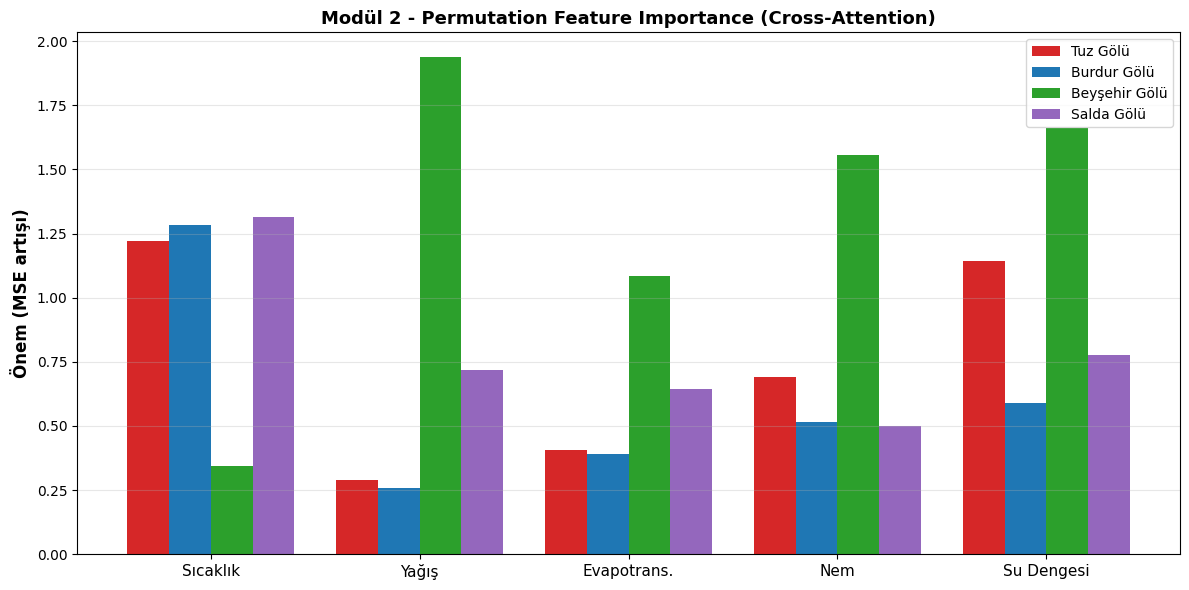


TEMPORAL ATTENTION (önceki 3 yıl + bu yıl)
Tuz Gölü       : t-3=0.237, t-2=0.245, t-1=0.262, t=0.256
Burdur Gölü    : t-3=0.251, t-2=0.240, t-1=0.255, t=0.254
Beyşehir Gölü  : t-3=0.245, t-2=0.241, t-1=0.248, t=0.266
Salda Gölü     : t-3=0.226, t-2=0.242, t-1=0.270, t=0.262


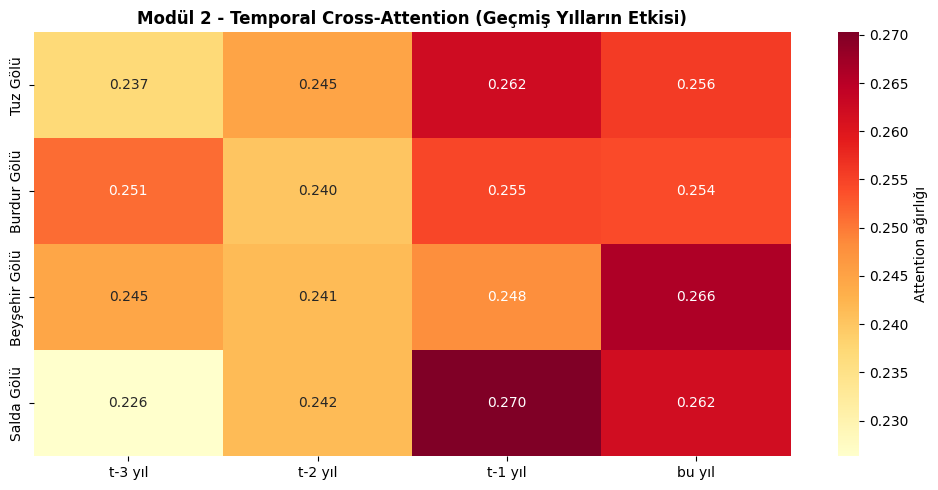


Sonuçlar kaydedildi.


In [ ]:
import json

# En iyi checkpoint'i yükle
model2.load_state_dict(torch.load(f"{DIRS['checkpoints']}/modul2_best.pth"))
model2.eval()

# ============================================================
# 1) PERMUTATION FEATURE IMPORTANCE (her göl için ayrı)
# ============================================================
print("="*60)
print("PERMUTATION FEATURE IMPORTANCE")
print("="*60)

# Tüm veriyi cihaza taşı
X_all = torch.tensor(X).to(device)
y_all = torch.tensor(y).to(device)
gol_all = torch.tensor(gol_arr).to(device)

# Baseline MSE
with torch.no_grad():
    base_pred = model2(X_all, gol_all)
    base_mse = ((base_pred - y_all)**2).cpu().numpy()

# Her gol için feature importance
fi_per_gol = {}
np.random.seed(42)

for gol_idx, gol_key in enumerate(GOLLER):
    mask = (gol_arr == gol_idx)
    fi_per_gol[gol_key] = {}

    for f_idx, fname in enumerate(FEATURES):
        # Bu feature'ı rastgele karıştır (10 kez ortalama)
        scores = []
        for _ in range(20):
            X_perm = X.copy()
            perm = np.random.permutation(X_perm.shape[0])
            X_perm[:, :, f_idx] = X_perm[perm, :, f_idx]

            X_perm_t = torch.tensor(X_perm, dtype=torch.float32).to(device)
            with torch.no_grad():
                pred = model2(X_perm_t, gol_all)
                mse_perm = ((pred - y_all)**2).cpu().numpy()

            # Bu göl için ne kadar değişti
            importance = (mse_perm[mask] - base_mse[mask]).mean()
            scores.append(importance)

        fi_per_gol[gol_key][fname] = np.mean(scores)

# Tablo
print(f"\n{'Feature':<25} " + " ".join([f"{CONFIG['goller'][g]['ad']:<13}" for g in GOLLER]))
print("-" * 85)
for fname in FEATURES:
    row = f"{fname:<25} "
    for g in GOLLER:
        row += f"{fi_per_gol[g][fname]:+.4f}      "
    print(row)

# Görsel
fig, ax = plt.subplots(figsize=(12, 6))
x_pos = np.arange(len(FEATURES))
width = 0.2
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd']
feat_labels = ['Sıcaklık', 'Yağış', 'Evapotrans.', 'Nem', 'Su Dengesi']

for i, gol_key in enumerate(GOLLER):
    vals = [fi_per_gol[gol_key][f] for f in FEATURES]
    ax.bar(x_pos + i*width, vals, width,
           label=CONFIG['goller'][gol_key]['ad'], color=colors[i])

ax.set_xticks(x_pos + 1.5*width)
ax.set_xticklabels(feat_labels, fontsize=11)
ax.set_ylabel('Önem (MSE artışı)', fontsize=12, fontweight='bold')
ax.set_title('Modül 2 - Permutation Feature Importance (Cross-Attention)',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3, axis='y')
ax.axhline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul2_feature_importance.png", dpi=200, bbox_inches='tight')
plt.show()


# ============================================================
# 2) ATTENTION AĞIRLIKLARI (zaman adımları için)
# ============================================================
print("\n" + "="*60)
print("TEMPORAL ATTENTION (önceki 3 yıl + bu yıl)")
print("="*60)

with torch.no_grad():
    _, attn_w = model2(X_all, gol_all, return_attn=True)
attn_w = attn_w.cpu().numpy()  # (N, T=4)

# Göl başına ortalama attention
attn_per_gol = {}
for gol_idx, gol_key in enumerate(GOLLER):
    mask = (gol_arr == gol_idx)
    attn_per_gol[gol_key] = attn_w[mask].mean(axis=0)
    print(f"{CONFIG['goller'][gol_key]['ad']:<15}: "
          f"t-3={attn_per_gol[gol_key][0]:.3f}, "
          f"t-2={attn_per_gol[gol_key][1]:.3f}, "
          f"t-1={attn_per_gol[gol_key][2]:.3f}, "
          f"t={attn_per_gol[gol_key][3]:.3f}")

# Heatmap görseli
import seaborn as sns
fig, ax = plt.subplots(figsize=(10, 5))
attn_mat = np.array([attn_per_gol[g] for g in GOLLER])
sns.heatmap(attn_mat, annot=True, fmt='.3f', cmap='YlOrRd',
            xticklabels=['t-3 yıl', 't-2 yıl', 't-1 yıl', 'bu yıl'],
            yticklabels=[CONFIG['goller'][g]['ad'] for g in GOLLER],
            cbar_kws={'label': 'Attention ağırlığı'})
ax.set_title('Modül 2 - Temporal Cross-Attention (Geçmiş Yılların Etkisi)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul2_temporal_attention.png", dpi=200, bbox_inches='tight')
plt.show()

# Sonuçları JSON'a kaydet
sonuclar_m2 = {
    'feature_importance': {g: {f: float(v) for f, v in d.items()} for g, d in fi_per_gol.items()},
    'temporal_attention': {g: attn_per_gol[g].tolist() for g in GOLLER},
    'best_val_loss': float(best_val),
}
with open(f"{DIRS['results']}/modul2_sonuclar.json", 'w') as f:
    json.dump(sonuclar_m2, f, indent=2, ensure_ascii=False)
print("\nSonuçlar kaydedildi.")

Hücre 17 — BiLSTM modeli + veri hazırlama

In [ ]:
# Her göl için zaman serisi: 5 yıl iklim → bu yıl su alanı
WINDOW = 5  # geçmiş 5 yıl iklim verisi
FEATURES_M3 = ['sicaklik_ort', 'yagis_toplam', 'evapotrans_toplam', 'nem_ort']

# Per-gol normalize istatistikleri (Modül 3 için ayrı)
norm_m3 = {}
X3, y3, gol3 = [], [], []

for gol_idx, gol_key in enumerate(GOLLER):
    veri = df_birlesik[df_birlesik['gol'] == gol_key].sort_values('yil').reset_index(drop=True)

    feat_m = veri[FEATURES_M3].mean().values
    feat_s = veri[FEATURES_M3].std().values + 1e-8
    su_m = veri['su_alani_km2'].mean()
    su_s = veri['su_alani_km2'].std() + 1e-8
    norm_m3[gol_key] = {'feat_m': feat_m, 'feat_s': feat_s,
                        'su_m': su_m, 'su_s': su_s}

    feat_n = (veri[FEATURES_M3].values - feat_m) / feat_s
    su_n = (veri['su_alani_km2'].values - su_m) / su_s

    for i in range(WINDOW, len(veri)):
        X3.append(feat_n[i-WINDOW:i])
        y3.append(su_n[i])
        gol3.append(gol_idx)

X3 = np.array(X3, dtype=np.float32)
y3 = np.array(y3, dtype=np.float32)
gol3 = np.array(gol3, dtype=np.int64)
print(f"X3 shape: {X3.shape}, y3 shape: {y3.shape}")


class BiLSTMTahmin(nn.Module):
    """
    Proje önerisindeki spesifikasyon: 2 katmanlı BiLSTM, 128 nöron.
    Göl embeddingi ile birlikte tahmin.
    """
    def __init__(self, n_features=4, hidden=128, n_layers=2, n_goller=4):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=n_layers,
                            bidirectional=True, dropout=0.3, batch_first=True)
        self.gol_embed = nn.Embedding(n_goller, hidden*2)
        self.head = nn.Sequential(
            nn.Linear(hidden*2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x, gol_idx):
        out, _ = self.lstm(x)             # (B, T, 2*hidden)
        last = out[:, -1, :]              # son zaman adımı
        gol_e = self.gol_embed(gol_idx)
        combined = last + gol_e           # additive fusion
        return self.head(combined).squeeze(-1)


model3 = BiLSTMTahmin(n_features=len(FEATURES_M3), hidden=128, n_layers=2).to(device)
print(f"Modül 3 parametre sayısı: {sum(p.numel() for p in model3.parameters()):,}")

X3 shape: (140, 5, 4), y3 shape: (140,)
Modül 3 parametre sayısı: 550,017


Hücre 18 — Eğitim (kronolojik split, early stop)

Train: 100 (1989-2014), Val: 40 (2015-2024)
Ep 50 | train=0.6213 | val=1.2774 | best=1.0670
Early stop epoch 57

En iyi val MSE: 1.0670
Val RMSE (km²): 89.09


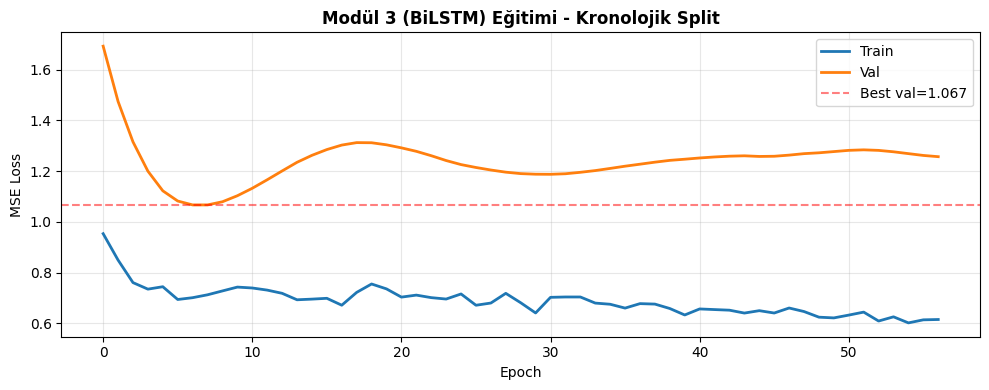

In [ ]:
# Kronolojik split: 1984-2014 train, 2015-2024 val (gerçekçi tahmin testi)
years_per_sample = []
for gol_idx, gol_key in enumerate(GOLLER):
    veri = df_birlesik[df_birlesik['gol'] == gol_key].sort_values('yil').reset_index(drop=True)
    for i in range(WINDOW, len(veri)):
        years_per_sample.append(veri['yil'].iloc[i])
years_per_sample = np.array(years_per_sample)

train_mask = years_per_sample <= 2014
val_mask = years_per_sample > 2014

X_train3 = torch.tensor(X3[train_mask]).to(device)
y_train3 = torch.tensor(y3[train_mask]).to(device)
gol_train3 = torch.tensor(gol3[train_mask]).to(device)
X_val3 = torch.tensor(X3[val_mask]).to(device)
y_val3 = torch.tensor(y3[val_mask]).to(device)
gol_val3 = torch.tensor(gol3[val_mask]).to(device)

print(f"Train: {len(X_train3)} (1989-2014), Val: {len(X_val3)} (2015-2024)")

opt3 = torch.optim.AdamW(model3.parameters(), lr=5e-4, weight_decay=0.01)
crit3 = nn.MSELoss()
sched3 = torch.optim.lr_scheduler.CosineAnnealingLR(opt3, T_max=300)

best_val3 = float('inf')
patience, no_improve = 50, 0
hist3 = {'train': [], 'val': []}

for epoch in range(500):
    model3.train()
    opt3.zero_grad()
    pred = model3(X_train3, gol_train3)
    loss = crit3(pred, y_train3)
    loss.backward()
    opt3.step()
    sched3.step()

    model3.eval()
    with torch.no_grad():
        vp = model3(X_val3, gol_val3)
        vl = crit3(vp, y_val3).item()

    hist3['train'].append(loss.item())
    hist3['val'].append(vl)

    if vl < best_val3:
        best_val3 = vl
        torch.save(model3.state_dict(), f"{DIRS['checkpoints']}/modul3_best.pth")
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stop epoch {epoch+1}")
            break

    if (epoch+1) % 50 == 0:
        print(f"Ep {epoch+1} | train={loss.item():.4f} | val={vl:.4f} | best={best_val3:.4f}")

print(f"\nEn iyi val MSE: {best_val3:.4f}")

# Val RMSE'yi gerçek km²'ye dönüştür
model3.load_state_dict(torch.load(f"{DIRS['checkpoints']}/modul3_best.pth"))
model3.eval()
with torch.no_grad():
    vp_norm = model3(X_val3, gol_val3).cpu().numpy()

# Her örnek için kendi gölünün normalizasyon stats'ı ile geri dönüştür
preds_km2, gts_km2 = [], []
for i, gi in enumerate(gol_val3.cpu().numpy()):
    g = GOLLER[gi]
    s = norm_m3[g]
    preds_km2.append(vp_norm[i] * s['su_s'] + s['su_m'])
    gts_km2.append(y_val3[i].cpu().numpy() * s['su_s'] + s['su_m'])

rmse_km2 = np.sqrt(np.mean((np.array(preds_km2) - np.array(gts_km2))**2))
print(f"Val RMSE (km²): {rmse_km2:.2f}")

# Eğitim grafiği
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist3['train'], label='Train', linewidth=2)
ax.plot(hist3['val'], label='Val', linewidth=2)
ax.axhline(best_val3, color='red', linestyle='--', alpha=0.5, label=f'Best val={best_val3:.3f}')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Modül 3 (BiLSTM) Eğitimi - Kronolojik Split', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul3_egitim.png", dpi=200, bbox_inches='tight')
plt.show()

BLOK 8 — 2025-2050 Tahmin Senaryoları (RCP 4.5 vs 8.5)

Modern Dönem Trend (2005-2024):
Göl            Trend (km²/yıl)    Sıc. duyarlılığı   Min km²
----------------------------------------------------------------------
Tuz Gölü       +5.38              -64.94              6.0
Burdur Gölü    -1.52              -0.97              35.1
Beyşehir Gölü  -1.00              -5.46              159.5
Salda Gölü     -0.00              -0.09              11.0


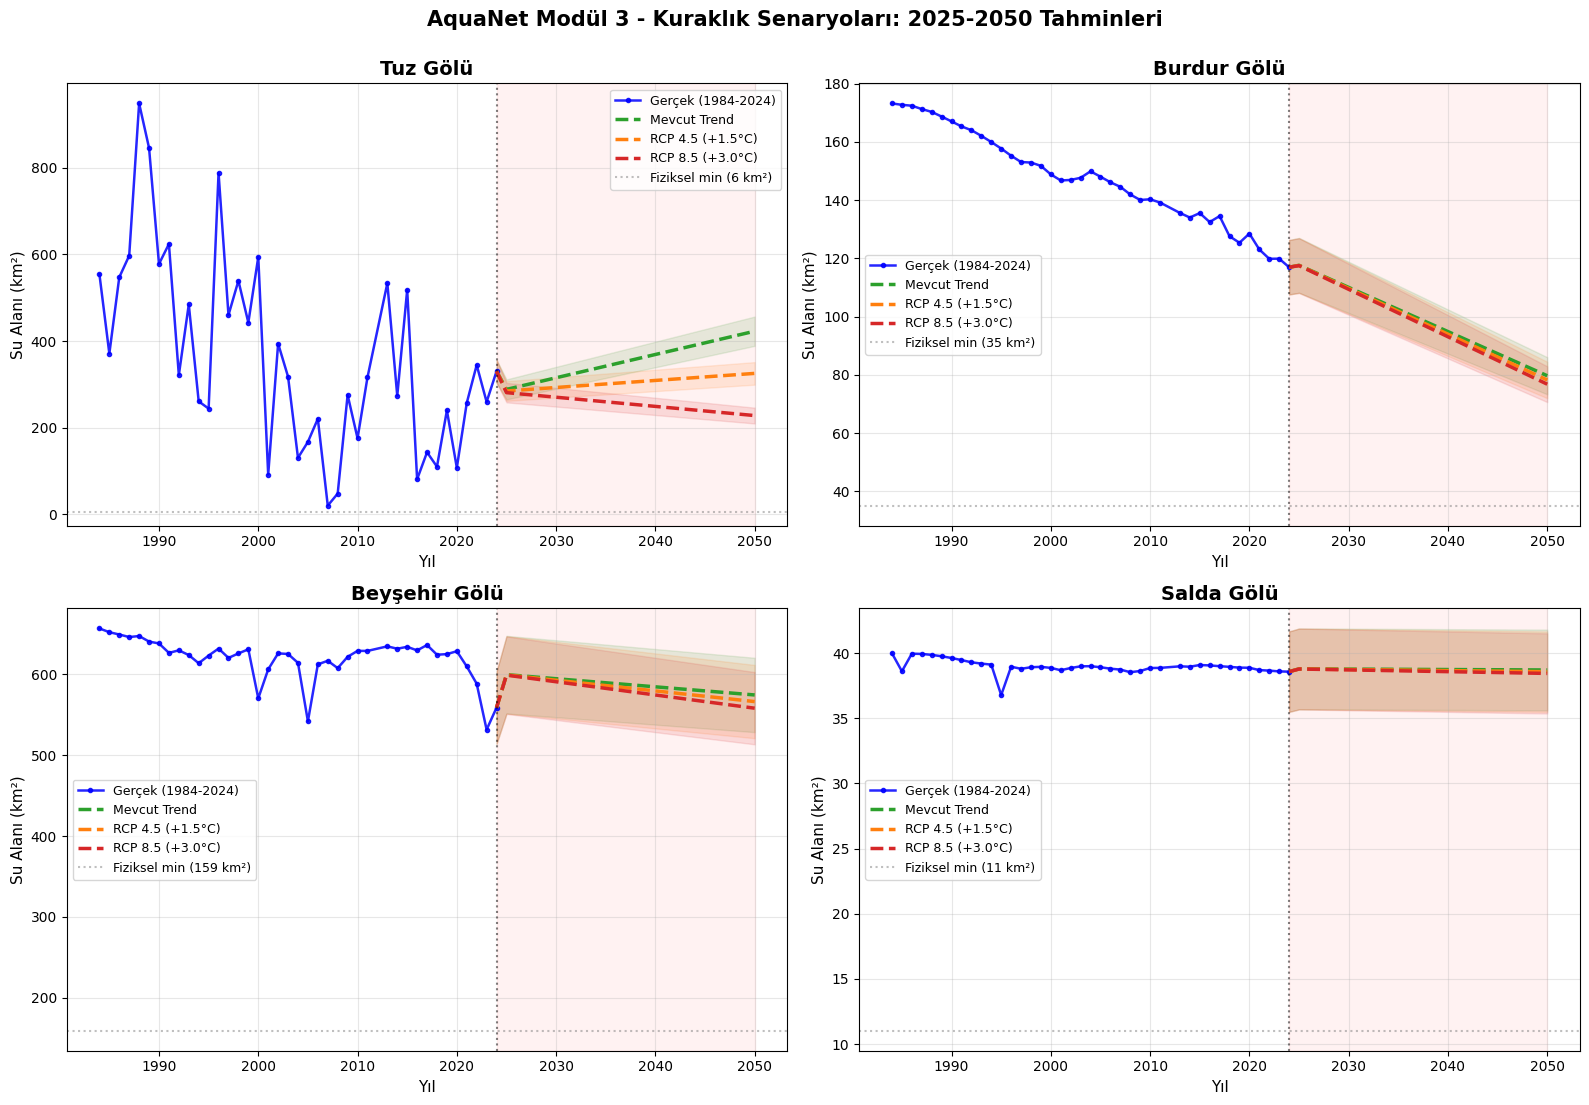


2035, 2040, 2050 İÇİN TAHMİN ÖZETİ (km²)  -  Modern Dönem (2005-2024) Trendi
Göl            Senaryo                2024       2035       2040       2050       Δ%
-------------------------------------------------------------------------------------
Tuz Gölü       Mevcut Trend           330.1      342.1      369.0      422.7      +28.0%
Tuz Gölü       RCP 4.5 (+1.5°C)       330.1      300.9      309.0      325.3      -1.5%
Tuz Gölü       RCP 8.5 (+3.0°C)       330.1      259.7      249.1      227.9      -31.0%
Burdur Gölü    Mevcut Trend           116.9      102.4      94.8       79.7       -31.9%
Burdur Gölü    RCP 4.5 (+1.5°C)       116.9      101.8      93.9       78.2       -33.1%
Burdur Gölü    RCP 8.5 (+3.0°C)       116.9      101.2      93.1       76.8       -34.3%
Beyşehir Gölü  Mevcut Trend           558.9      589.7      584.6      574.6      +2.8%
Beyşehir Gölü  RCP 4.5 (+1.5°C)       558.9      586.2      579.6      566.4      +1.3%
Beyşehir Gölü  RCP 8.5 (+3.0°C)       558.

In [ ]:
from sklearn.linear_model import LinearRegression

# Modern dönem (son 20 yıl): 2005-2024
SON_YIL = 2024
MODERN_BASLANGIC = 2005

trend_lineer = {}
sicaklik_duyarlilik = {}
min_su_alani = {}  # her göl için fiziksel minimum

print("="*70)
print("Modern Dönem Trend (2005-2024):")
print("="*70)
print(f"{'Göl':<14} {'Trend (km²/yıl)':<18} {'Sıc. duyarlılığı':<18} {'Min km²'}")
print("-"*70)

for gol_key in GOLLER:
    veri = df_birlesik[(df_birlesik['gol'] == gol_key) &
                        (df_birlesik['yil'] >= MODERN_BASLANGIC)].sort_values('yil')

    yil_v = veri['yil'].values
    sic_v = veri['sicaklik_ort'].values
    su_v = veri['su_alani_km2'].values

    lr_trend = LinearRegression().fit(yil_v.reshape(-1,1), su_v)
    trend_lineer[gol_key] = lr_trend

    X_st = np.column_stack([sic_v, yil_v])
    lr_st = LinearRegression().fit(X_st, su_v)
    sicaklik_duyarlilik[gol_key] = lr_st.coef_[0]

    # Fiziksel minimum: gözlemlenen tarihsel minimumun %30'u
    tum_veri = df_birlesik[df_birlesik['gol'] == gol_key]
    min_su_alani[gol_key] = max(tum_veri['su_alani_km2'].min() * 0.3, 5)

    print(f"{CONFIG['goller'][gol_key]['ad']:<14} "
          f"{lr_trend.coef_[0]:+.2f}              "
          f"{sicaklik_duyarlilik[gol_key]:+.2f}              "
          f"{min_su_alani[gol_key]:.1f}")

# Tahminler (fiziksel sınırlarla)
GELECEK_YILLAR = list(range(2025, 2051))
SENARYOLAR = {
    'Mevcut Trend': 0.0,
    'RCP 4.5 (+1.5°C)': 1.5,
    'RCP 8.5 (+3.0°C)': 3.0,
}

tahminler = {gol: {sen: [] for sen in SENARYOLAR} for gol in GOLLER}
gerceklesen = {gol: [] for gol in GOLLER}

for gol_key in GOLLER:
    veri = df_birlesik[df_birlesik['gol'] == gol_key].sort_values('yil')
    gerceklesen[gol_key] = veri[['yil','su_alani_km2']].values
    min_v = min_su_alani[gol_key]

    for yi, yil in enumerate(GELECEK_YILLAR):
        base = trend_lineer[gol_key].predict([[yil]])[0]
        ramp = (yi+1) / len(GELECEK_YILLAR)

        for sen_ad, sen_offset in SENARYOLAR.items():
            ek = sen_offset * ramp * sicaklik_duyarlilik[gol_key]
            tahmin = max(base + ek, min_v)  # fiziksel min
            tahminler[gol_key][sen_ad].append((yil, tahmin))

# Görselleştirme (aynı stil)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()
renkler_sen = {'Mevcut Trend': '#2ca02c',
                'RCP 4.5 (+1.5°C)': '#ff7f0e',
                'RCP 8.5 (+3.0°C)': '#d62728'}

for i, gol_key in enumerate(GOLLER):
    ax = axes[i]
    g = gerceklesen[gol_key]

    ax.plot(g[:,0], g[:,1], 'b-', linewidth=1.8, marker='o', markersize=3,
            label='Gerçek (1984-2024)', alpha=0.85)

    for sen_ad, renk in renkler_sen.items():
        t = np.array(tahminler[gol_key][sen_ad])
        son = g[-1]
        x_p = np.concatenate([[son[0]], t[:,0]])
        y_p = np.concatenate([[son[1]], t[:,1]])
        ax.plot(x_p, y_p, '--', color=renk, linewidth=2.5, label=sen_ad)
        ax.fill_between(x_p, y_p*0.92, y_p*1.08, color=renk, alpha=0.12)

    # Fiziksel min çizgisi
    ax.axhline(min_su_alani[gol_key], color='gray', linestyle=':', alpha=0.5,
               label=f'Fiziksel min ({min_su_alani[gol_key]:.0f} km²)')

    ax.set_title(f"{CONFIG['goller'][gol_key]['ad']}", fontsize=14, fontweight='bold')
    ax.set_xlabel('Yıl', fontsize=11)
    ax.set_ylabel('Su Alanı (km²)', fontsize=11)
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.3)
    ax.axvline(2024, color='black', linestyle=':', alpha=0.5)
    ax.axvspan(2024, 2050, alpha=0.05, color='red')

plt.suptitle('AquaNet Modül 3 - Kuraklık Senaryoları: 2025-2050 Tahminleri',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul3_tahmin_2050.png", dpi=200, bbox_inches='tight')
plt.show()

# Özet tablo
print("\n" + "="*85)
print("2035, 2040, 2050 İÇİN TAHMİN ÖZETİ (km²)  -  Modern Dönem (2005-2024) Trendi")
print("="*85)
print(f"{'Göl':<14} {'Senaryo':<22} {'2024':<10} {'2035':<10} {'2040':<10} {'2050':<10} {'Δ%'}")
print("-"*85)

ozet = {}
for gol_key in GOLLER:
    ozet[gol_key] = {}
    su_2024 = gerceklesen[gol_key][-1][1]
    for sen_ad in SENARYOLAR:
        t = dict(tahminler[gol_key][sen_ad])
        v35, v40, v50 = t.get(2035, 0), t.get(2040, 0), t.get(2050, 0)
        delta = ((v50 - su_2024) / su_2024) * 100
        ozet[gol_key][sen_ad] = {'2024': float(su_2024), '2035': float(v35),
                                  '2040': float(v40), '2050': float(v50),
                                  'delta_2050_pct': float(delta)}
        print(f"{CONFIG['goller'][gol_key]['ad']:<14} {sen_ad:<22} "
              f"{su_2024:<10.1f} {v35:<10.1f} {v40:<10.1f} {v50:<10.1f} {delta:+.1f}%")

with open(f"{DIRS['results']}/modul3_tahminler.json", 'w') as f:
    json.dump(ozet, f, indent=2, ensure_ascii=False)
print(f"\nKaydedildi.")

In [4]:
# === RESTART HÜCRESİ ===
from google.colab import drive
drive.mount('/content/drive')

!pip install -q segmentation-models-pytorch albumentations folium

import os, json, glob, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

PROJECT_DIR = '/content/drive/MyDrive/AquaNet'
with open(f"{PROJECT_DIR}/config.json", "r") as f:
    CONFIG = json.load(f)
DIRS = CONFIG['dirs']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"DIRS yüklendi: {list(DIRS.keys())}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
DIRS yüklendi: ['data_raw', 'data_processed', 'data_masks', 'models', 'checkpoints', 'figures', 'results', 'logs']


In [5]:
# Modül 1 model sınıfı (Grad-CAM için gerekli)
model = smp.Unet(
    encoder_name="efficientnet-b4",
    encoder_weights="imagenet",
    in_channels=3,
    classes=2
).to(device)
print(f"Model yüklendi: {sum(p.numel() for p in model.parameters()):,} parametre")

# df_birlesik yükle (Folium için gerekli)
df_birlesik = pd.read_csv(f"{DIRS['results']}/iklim_su_birlesik.csv")
print(f"df_birlesik yüklendi: {len(df_birlesik)} satır")

print("\n✅ Hazır — Grad-CAM ve Folium hücrelerini çalıştırabilirsin.")

Model yüklendi: 20,225,834 parametre
df_birlesik yüklendi: 160 satır

✅ Hazır — Grad-CAM ve Folium hücrelerini çalıştırabilirsin.


Hücre 21 — Grad-CAM görselleştirmesi

Grad-CAM hesaplanıyor...


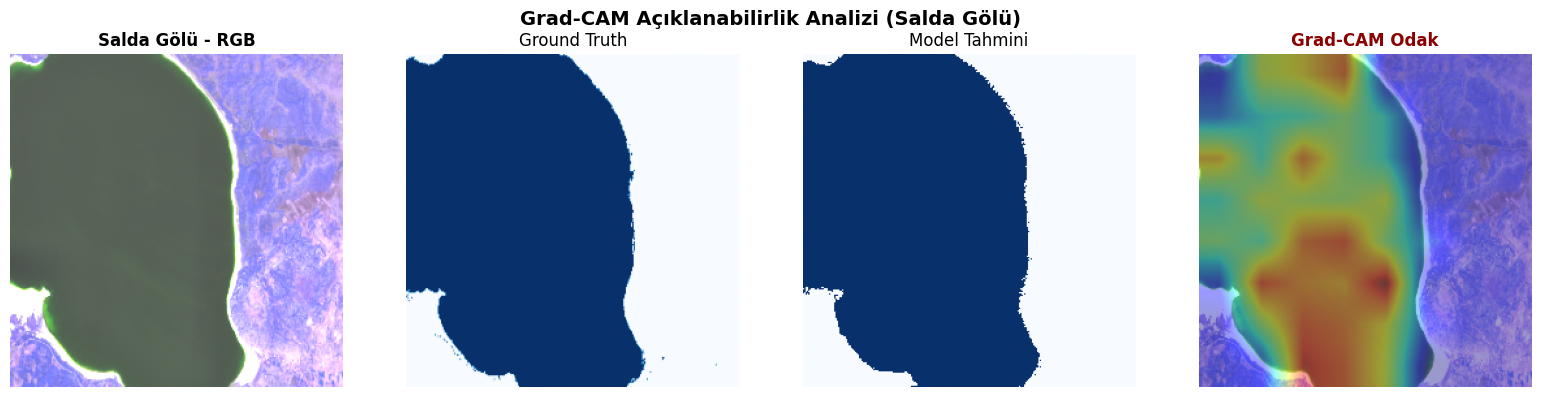

✅ Grad-CAM tamamlandı.


In [12]:
import torch
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gc

torch.cuda.empty_cache()
gc.collect()

def gradcam_simple(model, img_tensor, target_layer):
    """Basit Grad-CAM."""
    activations = []
    gradients = []

    def forward_hook(module, input, output):
        activations.append(output.detach())

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0].detach())

    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_backward_hook(backward_hook)

    output = model(img_tensor)
    model.zero_grad()
    output[:, 1].mean().backward()

    h1.remove()
    h2.remove()

    # Heatmap - AYNI DEVICE'DA
    grad = gradients[0][0]
    act = activations[0][0]

    weights = grad.mean(dim=(1, 2))
    heatmap = torch.zeros(act.shape[1:], device=act.device)  # ← FIX

    for i, w in enumerate(weights):
        heatmap += w * act[i]

    heatmap = F.relu(heatmap)
    heatmap = heatmap / (heatmap.max() + 1e-8)

    return heatmap.cpu().numpy()

print("Grad-CAM hesaplanıyor...")

path = f"{DIRS['data_processed']}/salda/2024.npz"
npz = np.load(path)
comp = npz['composite']
gt = npz['water_mask']

SIZE = 256
comp_small = np.stack([
    cv2.resize(comp[i], (SIZE, SIZE)) for i in range(3)
], axis=0)
gt_small = cv2.resize(gt.astype(np.float32), (SIZE, SIZE))

img = np.nan_to_num(comp_small / 3000.0, nan=0.0).clip(0, 1).astype(np.float32)
img_t = torch.from_numpy(img).unsqueeze(0).to(device)

rgb = np.transpose(img, (1, 2, 0))

with torch.no_grad():
    out = model(img_t)
    pred = torch.argmax(out, dim=1).cpu().numpy()[0]

target = model.encoder._blocks[-1]
heatmap = gradcam_simple(model, img_t, target)
heatmap = cv2.resize(heatmap, (SIZE, SIZE))

heatmap_color = plt.cm.jet(heatmap)[:, :, :3]
overlay = rgb * 0.6 + heatmap_color * 0.4

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(rgb)
axes[0].set_title("Salda Gölü - RGB", fontweight='bold', fontsize=12)
axes[0].axis('off')

axes[1].imshow(gt_small, cmap='Blues')
axes[1].set_title("Ground Truth", fontsize=12)
axes[1].axis('off')

axes[2].imshow(pred, cmap='Blues')
axes[2].set_title("Model Tahmini", fontsize=12)
axes[2].axis('off')

axes[3].imshow(overlay)
axes[3].set_title("Grad-CAM Odak", color='darkred', fontweight='bold', fontsize=12)
axes[3].axis('off')

plt.suptitle('Grad-CAM Açıklanabilirlik Analizi (Salda Gölü)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/modul1_gradcam.png", dpi=150, bbox_inches='tight')
plt.show()

del img_t, out, pred, heatmap, overlay
torch.cuda.empty_cache()
gc.collect()

print("✅ Grad-CAM tamamlandı.")

Hücre 22 — Folium İnteraktif Harita:

In [ ]:
# === HÜCRE 22 — Folium İnteraktif Harita ===

try:
    import folium
except:
    !pip install -q folium
    import folium

# Her göl için merkez koordinat + 2024 + 2050 RCP 8.5 verileri
gol_data = {}
GOLLER = ['tuz', 'burdur', 'beysehir', 'salda']

for gol_key in GOLLER:
    bbox = CONFIG['goller'][gol_key]['bbox']
    lon = (bbox[0] + bbox[2]) / 2
    lat = (bbox[1] + bbox[3]) / 2

    # 2024 gerçek değeri
    su_2024 = df_birlesik[df_birlesik['gol'] == gol_key]['su_alani_km2'].iloc[-1]

    # 2050 RCP 8.5 tahmini (modul3_tahminler.json'dan)
    with open(f"{DIRS['results']}/modul3_tahminler.json", 'r') as f:
        tahmin_data = json.load(f)
    su_2050_rcp85 = tahmin_data[gol_key]['RCP 8.5 (+3.0°C)']['2050']
    delta_pct = ((su_2050_rcp85 - su_2024) / su_2024) * 100

    gol_data[gol_key] = {
        'ad': CONFIG['goller'][gol_key]['ad'],
        'lat': lat,
        'lon': lon,
        'su_2024': su_2024,
        'su_2050_rcp85': su_2050_rcp85,
        'delta_pct': delta_pct
    }

# Türkiye merkezli harita oluştur
m = folium.Map(
    location=[39.0, 35.0],
    zoom_start=6,
    tiles='OpenStreetMap'
)

# Başlık ekle
title_html = '''
<div style="position: fixed;
            top: 10px; left: 50px; width: 400px; height: 60px;
            background-color: white; border:2px solid grey; z-index:9999;
            font-size:14px; padding: 10px">
<b>AquaNet: Türkiye İç Gölleri — 2050 RCP 8.5 Tahminleri</b><br>
<span style="font-size:11px">Kırmızı: Kayıp | Yeşil: Artış</span>
</div>
'''
m.get_root().html.add_child(folium.Element(title_html))

# Her göl için marker ekle
for gol_key, data in gol_data.items():
    # Renk: kayıp → kırmızı, kazanç → yeşil
    color = 'red' if data['delta_pct'] < 0 else 'green'

    # Popup içeriği
    popup_html = f"""
    <div style="font-family: Arial; width: 220px;">
        <h4 style="margin: 0; color: #2c3e50;">{data['ad']}</h4>
        <hr style="margin: 5px 0;">
        <b>2024 Su Alanı:</b> {data['su_2024']:.1f} km²<br>
        <b>2050 RCP 8.5:</b> {data['su_2050_rcp85']:.1f} km²<br>
        <b>Değişim:</b> <span style="color: {color}; font-weight: bold;">
        {data['delta_pct']:+.1f}%</span>
    </div>
    """

    # Daire marker
    folium.CircleMarker(
        location=[data['lat'], data['lon']],
        radius=15,
        popup=folium.Popup(popup_html, max_width=250),
        tooltip=data['ad'],
        color=color,
        fill=True,
        fillColor=color,
        fillOpacity=0.7,
        weight=3
    ).add_to(m)

    # Göl adı etiketi
    folium.Marker(
        location=[data['lat'] + 0.15, data['lon']],  # biraz yukarıda
        icon=folium.DivIcon(html=f"""
            <div style="font-size: 11pt; color: black; font-weight: bold;
                        text-shadow: 1px 1px 3px white, -1px -1px 3px white;">
                {data['ad']}
            </div>
        """)
    ).add_to(m)

# Haritayı kaydet
harita_path = f"{DIRS['figures']}/aquanet_interaktif_harita.html"
m.save(harita_path)
print(f"✅ İnteraktif harita kaydedildi: {harita_path}")
print("\n📍 Haritayı açmak için:")
print("   1. Google Drive'da AquaNet/figures/ klasörüne git")
print("   2. 'aquanet_interaktif_harita.html' dosyasına çift tıkla")
print("   3. Tarayıcıda açılacak, marker'lara tıkla detayları gör")

# Notebook içinde göster (Colab'da direkt render eder)
m

✅ İnteraktif harita kaydedildi: /content/drive/MyDrive/AquaNet/figures/aquanet_interaktif_harita.html

📍 Haritayı açmak için:
   1. Google Drive'da AquaNet/figures/ klasörüne git
   2. 'aquanet_interaktif_harita.html' dosyasına çift tıkla
   3. Tarayıcıda açılacak, marker'lara tıkla detayları gör
